# NYC Yellow Taxi Trips 2023: Exploratory Data Analysis

**Rishabh Jain**

This notebook analyses a stratified sample of the 38.3 million yellow taxi trips recorded in New York City in 2023. It covers sampling, data cleaning, demand patterns, revenue, geography, operations, pricing and customer behaviour, and ends with recommendations for dispatch, positioning and pricing.

* The trip records and zone shapefile come from the [NYC Taxi and Limousine Commission](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page). Run `python scripts/download_data.py` from the repository root to download them.
* Charts are saved to `docs/figures` when the notebook runs.
* The [report](../docs/report.md) summarises the findings, and the [notes](../docs/notes.md) explain the methods.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from matplotlib.colors import LogNorm

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")

In [3]:
for module in [np, pd, plt.matplotlib, sns, gpd]:
    print(f"{module.__name__}: {module.__version__}")

numpy: 2.5.3
pandas: 3.0.6
matplotlib: 3.11.2
seaborn: 0.13.2
geopandas: 1.2.0


In [4]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
TRIPS_DIR = ROOT / "data" / "raw" / "trip_records"
ZONES_FILE = ROOT / "data" / "raw" / "taxi_zones" / "taxi_zones.shp"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "docs" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_FRACTION = 0.0075
SEED = 42
NIGHT_HOURS = [23, 0, 1, 2, 3, 4]
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONEY_COLS = ["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
              "improvement_surcharge", "total_amount", "congestion_surcharge", "airport_fee"]
SURCHARGES = ["extra", "mta_tax", "tolls_amount", "improvement_surcharge",
              "congestion_surcharge", "airport_fee"]
PAYMENT_LABELS = {0: "Not recorded", 1: "Credit card", 2: "Cash", 3: "No charge",
                  4: "Dispute", 5: "Unknown", 6: "Voided trip"}
VENDOR_LABELS = {1: "Creative Mobile Technologies", 2: "VeriFone", 6: "Vendor 6"}


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Data and sampling

Each monthly file holds about 3 million trips. Combining all twelve months would mean 38.3 million rows, which is slow to clean and plot on a laptop. The analysis therefore uses a stratified random sample.

* The sample draws 0.75% of trips from every pickup date and hour, so each part of the day and year keeps its true weight.
* Sampling by date and hour, rather than by hour alone, keeps busy days, holidays and quiet days in proportion.

In [5]:
january = pd.read_parquet(TRIPS_DIR / "yellow_tripdata_2023-01.parquet")
january.info()

<class 'pandas.DataFrame'>
RangeIndex: 3066766 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            float64   

In [6]:
files = sorted(TRIPS_DIR.glob("yellow_tripdata_2023-*.parquet"))
population = pd.Series({f.stem[-2:]: pq.ParquetFile(f).metadata.num_rows for f in files}, name="trips")
print(f"Trips recorded in 2023: {population.sum():,}")
population.to_frame().T

Trips recorded in 2023: 38,310,226


,01,02,03,04,05,06,07,08,09,10,11,12
trips,3066766,2913955,3403766,3288250,3513649,3307234,2907108,2824209,2846722,3522285,3339715,3376567


In [7]:
def sample_month(path):
    month = pd.read_parquet(path)
    pickup = month["tpep_pickup_datetime"]
    groups = [pickup.dt.date.rename("pickup_date"), pickup.dt.hour.rename("pickup_hour")]
    return month.groupby(groups, group_keys=False).sample(frac=SAMPLE_FRACTION, random_state=SEED)


df = pd.concat([sample_month(f) for f in files])
print(f"Sampled trips: {len(df):,} ({len(df) / population.sum():.2%} of all 2023 trips)")

sample_check = pd.DataFrame({
    "population_share": population / population.sum(),
    "sample_share": df["tpep_pickup_datetime"].dt.strftime("%m").value_counts() / len(df),
}).mul(100).round(2)
sample_check

Sampled trips: 287,296 (0.75% of all 2023 trips)


,population_share,sample_share
01,8.01,8.01
02,7.61,7.60
03,8.88,8.88
04,8.58,8.58
05,9.17,9.17
06,8.63,8.63
07,7.59,7.59
08,7.37,7.37
09,7.43,7.43
10,9.19,9.20


**Observations**

* The sample contains 287,296 trips, which is 0.75% of the 38,310,226 trips recorded in 2023.
* Each month's share of the sample matches its share of all trips to within 0.01 percentage points, so the sample keeps the true seasonal mix.

In [8]:
df.to_parquet(PROCESSED_DIR / "trips_sample.parquet")

## 3. Data cleaning

### 3.1 Fixing columns

In [9]:
df = df.reset_index(drop=True)
print(df["store_and_fwd_flag"].value_counts(dropna=False))
df = df.drop(columns="store_and_fwd_flag")

store_and_fwd_flag
N      275788
NaN      9847
Y        1661
Name: count, dtype: int64


In [10]:
both_filled = df["airport_fee"].notna() & df["Airport_fee"].notna()
print(f"Rows with a value in both columns: {both_filled.sum()}")
df["airport_fee"] = df["airport_fee"].combine_first(df["Airport_fee"])
df = df.drop(columns="Airport_fee")
print(f"Rows still missing airport_fee: {df['airport_fee'].isna().sum():,}")

Rows with a value in both columns: 0
Rows still missing airport_fee: 9,847


**Observations**

* `store_and_fwd_flag` only records whether a trip was stored offline before upload. Only 0.6% of trips are flagged `Y`, and the column is not needed for this analysis, so it is dropped.
* January's file names the airport fee `airport_fee`, while February to December use `Airport_fee`. No row has a value in both, so the two columns combine into one without conflicts.

### 3.2 Negative monetary values

In [11]:
negative_fares = df[df["fare_amount"] < 0]
print(f"Trips with a negative fare: {len(negative_fares):,} ({len(negative_fares) / len(df):.2%})")
negative_fares[["VendorID", "RatecodeID", "payment_type", "fare_amount", "total_amount"]].head()

Trips with a negative fare: 2,833 (0.99%)


,VendorID,RatecodeID,payment_type,fare_amount,total_amount
23,2,1.0,4,-17.7,-22.70
172,2,1.0,4,-17.7,-22.70
194,2,1.0,4,-35.9,-51.45
195,2,1.0,4,-3.0,-4.50
250,2,1.0,2,-105.9,-111.15


In [12]:
print(pd.DataFrame({
    "negative_fares": negative_fares["RatecodeID"].value_counts(normalize=True),
    "all_trips": df["RatecodeID"].value_counts(normalize=True),
}).mul(100).round(1))

for col in ["VendorID", "payment_type"]:
    print(col, negative_fares[col].value_counts(normalize=True).mul(100).round(1).to_dict())

key = ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "fare_amount"]
reversals = january.loc[january["fare_amount"] < 0, key].assign(fare_amount=lambda d: -d["fare_amount"])
twins = reversals.merge(january[key].drop_duplicates(), on=key)
print(f"January negative fares matching a positive trip: {len(twins) / len(reversals):.1%}")

            negative_fares  all_trips
RatecodeID                           
1.0                   89.2       94.3
2.0                    7.5        4.0
3.0                    1.1        0.3
4.0                    0.5        0.2
5.0                    1.7        0.6
99.0                   NaN        0.6
VendorID {2: 100.0}
payment_type {4: 59.3, 2: 23.5, 3: 15.7, 0: 1.5, 1: 0.1}


January negative fares matching a positive trip: 87.1%


In [13]:
(df[MONEY_COLS] < 0).sum().to_frame("negative_rows")

,negative_rows
fare_amount,2833
extra,1429
mta_tax,2733
tip_amount,12
tolls_amount,193
improvement_surcharge,2811
total_amount,2813
congestion_surcharge,2277
airport_fee,390


In [14]:
has_negative = (df[MONEY_COLS] < 0).any(axis=1)
print(f"Rows removed: {has_negative.sum():,} ({has_negative.mean():.2%})")
df = df[~has_negative].reset_index(drop=True)
del january

Rows removed: 2,855 (0.99%)


**Observations**

* About 1% of sampled trips have a negative fare. All of them come from VendorID 2 (VeriFone).
* Airport and other special rate codes are over-represented among them. Rate code 2 (JFK) makes up 7.5% of negative fares compared with 4.0% of all trips.
* Disputes, cash and no-charge payments account for 98.5% of these rows. In January, 87.1% of negative fares match a positive trip with the same pickup time, zones and amount.
* These rows are reversals of other trips rather than real journeys. Keeping them would cancel out revenue, so all 2,855 rows with any negative charge are removed.

### 3.3 Missing values

In [15]:
missing = df.isna().mean().mul(100).round(2)
missing[missing > 0].to_frame("missing_pct")

,missing_pct
passenger_count,3.45
RatecodeID,3.45
congestion_surcharge,3.45
airport_fee,3.45


In [16]:
missing_block = df["passenger_count"].isna()
print(f"Rows with a missing passenger_count: {missing_block.sum():,}")
print("Payment types in these rows:", df.loc[missing_block, "payment_type"].unique())
print("Other columns also missing:",
      df.loc[missing_block, ["RatecodeID", "congestion_surcharge", "airport_fee"]].isna().all().to_dict())

passenger_mode = df["passenger_count"].mode()[0]
df["passenger_count"] = df["passenger_count"].fillna(passenger_mode)

Rows with a missing passenger_count: 9,804
Payment types in these rows: [0]
Other columns also missing: {'RatecodeID': True, 'congestion_surcharge': True, 'airport_fee': True}


In [17]:
print(f"Trips with zero passengers: {(df['passenger_count'] == 0).sum():,}")
df["passenger_count"] = df["passenger_count"].replace(0, passenger_mode)

Trips with zero passengers: 4,324


In [18]:
print(df["RatecodeID"].value_counts(dropna=False))
ratecode_mode = df["RatecodeID"].mode()[0]
df["RatecodeID"] = df["RatecodeID"].replace(99, np.nan).fillna(ratecode_mode)

RatecodeID
1.0     259124
2.0      10849
NaN       9804
99.0      1583
5.0       1574
3.0        928
4.0        579
Name: count, dtype: int64


The congestion surcharge and airport fee are missing for the same rows. Their values can be recovered from the fare breakdown, because the total amount equals the sum of all charges. The difference between the total and the known charges shows which fees were applied.

In [19]:
components = ["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount", "improvement_surcharge"]
residual = (df["total_amount"] - df[components].sum(axis=1)).round(2)
missing_fee = df["congestion_surcharge"].isna()
print(residual[missing_fee].value_counts().head())
df.loc[missing_fee, "congestion_surcharge"] = np.where(residual[missing_fee] >= 2.5, 2.5, 0.0)

2.5    8774
0.0     930
4.5      97
2.0       3
Name: count, dtype: int64


In [20]:
missing_airport = df["airport_fee"].isna()
leftover = residual - df["congestion_surcharge"]
df.loc[missing_airport, "airport_fee"] = np.where(leftover[missing_airport] >= 1.75, 1.75, 0.0)
print(f"Missing values left: {df.isna().sum().sum()}")

Missing values left: 0

**Observations**

* Four columns are missing for the same 3.45% of trips. All of these trips have `payment_type` 0, which the 2023 data dictionary does not define.
* `passenger_count` is set to the mode of 1. The 4,324 trips that record zero passengers are also set to 1, because a paid trip carries at least one passenger.
* `RatecodeID` is set to the mode of 1 (standard rate). Code 99 is not defined in the data dictionary, so it is treated as missing.
* The fare breakdown shows a gap of $2.50 for 89% of the affected trips, which matches the congestion surcharge. The congestion surcharge and airport fee are therefore inferred from this gap rather than set to zero.

### 3.4 Outliers

,passenger_count,trip_distance,trip_duration_min,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
count,284441.00,284441.00,284441.00,284441.00,284441.00,284441.00,284441.00,284441.00,284441.00,284441.00,284441.00,284441.00
mean,1.38,3.79,17.52,19.92,1.58,0.50,3.56,0.59,1.00,28.99,2.31,0.14
std,0.87,93.56,41.08,18.24,1.83,0.05,4.05,2.16,0.03,22.79,0.67,0.46
min,1.00,0.00,-56.27,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1%,1.00,0.00,1.00,4.40,0.00,0.50,0.00,0.00,1.00,9.08,0.00,0.00
50%,1.00,1.80,12.70,13.50,1.00,0.50,2.85,0.00,1.00,21.10,2.50,0.00
99%,5.00,20.28,68.01,78.60,7.50,0.50,17.73,6.94,1.00,104.41,2.50,1.75
max,8.00,44409.66,1439.43,595.20,12.50,0.80,200.00,44.52,1.00,604.45,2.50,1.75


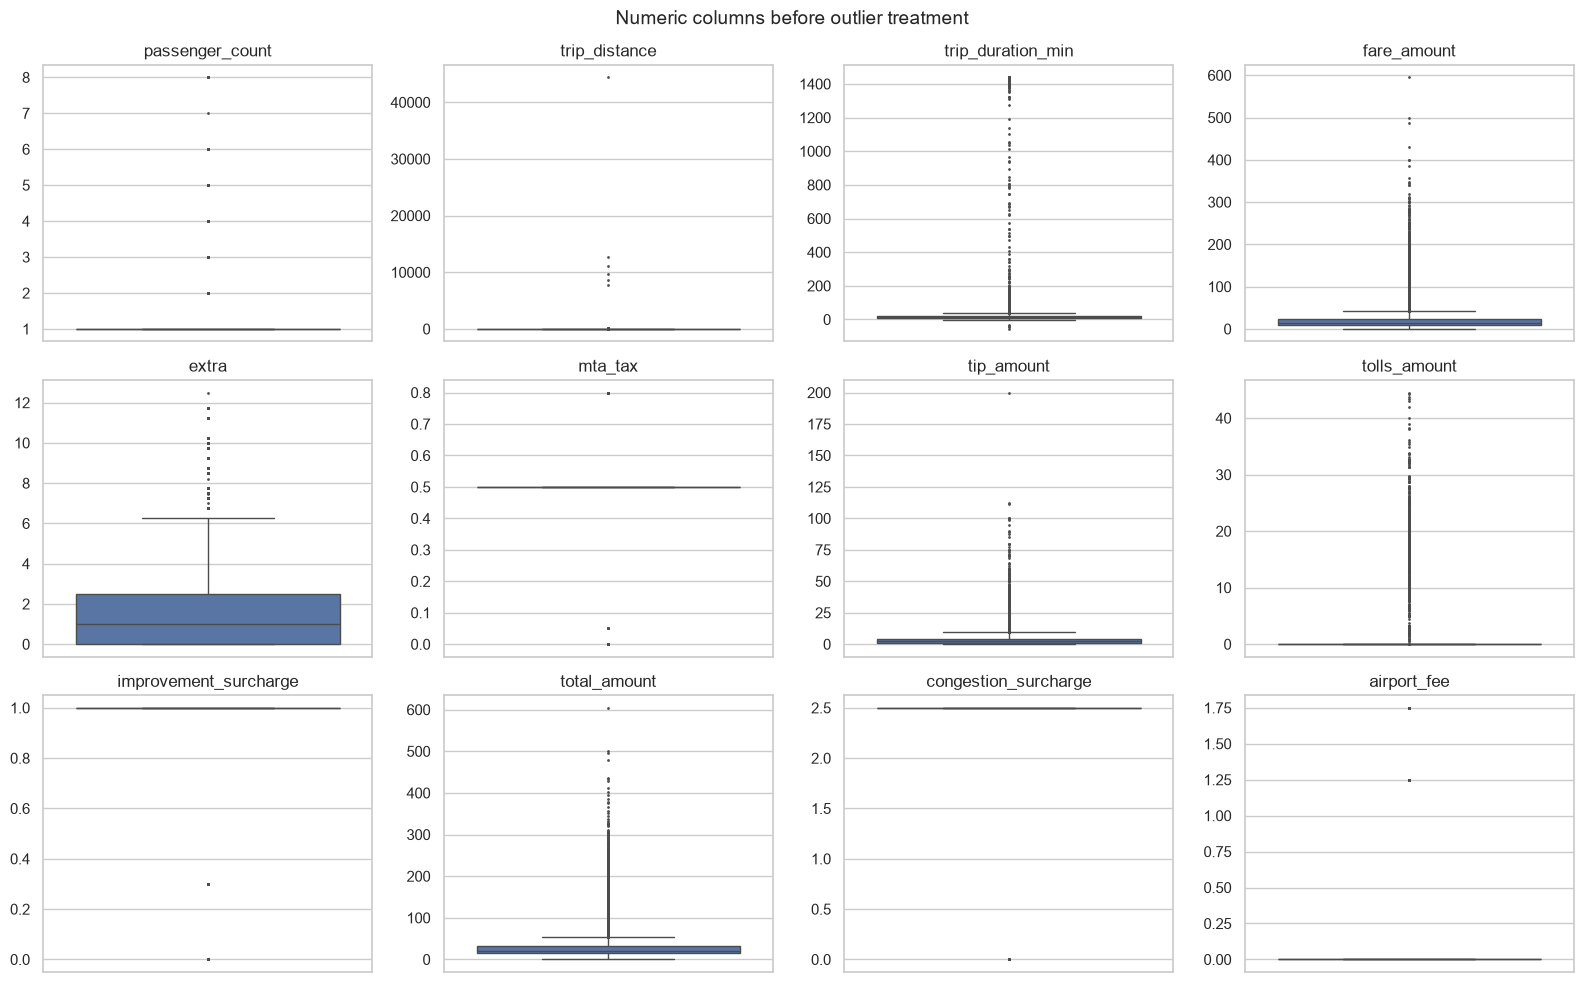

In [21]:
df["trip_duration_min"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
numeric_cols = ["passenger_count", "trip_distance", "trip_duration_min", *MONEY_COLS]
display(df[numeric_cols].describe(percentiles=[0.01, 0.5, 0.99]).round(2))


def plot_boxes(data, title):
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    for ax, col in zip(axes.flat, numeric_cols):
        sns.boxplot(y=data[col], ax=ax, color="#4C72B0", fliersize=1)
        ax.set(title=col, ylabel="")
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    return fig


fig = plot_boxes(df, "Numeric columns before outlier treatment")
save(fig, "outliers_before")
plt.show()

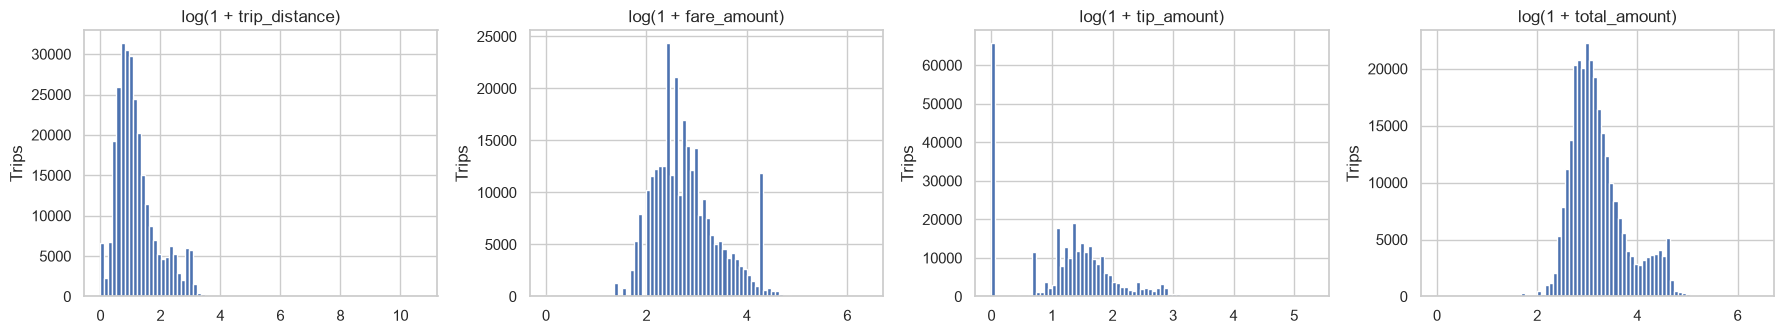

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, ["trip_distance", "fare_amount", "tip_amount", "total_amount"]):
    ax.hist(np.log1p(df[col]), bins=80, color="#4C72B0")
    ax.set(title=f"log(1 + {col})", ylabel="Trips")
fig.tight_layout()
plt.show()

In [23]:
speed_mph = df["trip_distance"] / (df["trip_duration_min"] / 60)
speed_mph.replace([np.inf, -np.inf], np.nan).describe(percentiles=[0.5, 0.99, 0.999]).round(1)

count    284339.0
mean         13.2
std         424.4
min      -13770.0
50%           9.6
99%          35.9
99.9%        48.6
max      190327.1
dtype: float64

In [24]:
print(df["passenger_count"].value_counts().sort_index())
df = df[df["passenger_count"] <= 6]
df = df.astype({"passenger_count": int, "RatecodeID": int})

passenger_count
1.0    220265
2.0     41931
3.0     10341
4.0      5821
5.0      3685
6.0      2391
7.0         1
8.0         6
Name: count, dtype: int64


In [25]:
speed_mph = df["trip_distance"] / (df["trip_duration_min"] / 60)
rules = {
    "Distance under 0.1 miles with a fare above $300": (df["trip_distance"] < 0.1) & (df["fare_amount"] > 300),
    "Zero distance and fare between different zones": (df["trip_distance"] == 0) & (df["fare_amount"] == 0)
                                                      & (df["PULocationID"] != df["DOLocationID"]),
    "Distance above 250 miles": df["trip_distance"] > 250,
    "Pickup outside 2023": df["tpep_pickup_datetime"].dt.year != 2023,
    "Duration of zero minutes or less": df["trip_duration_min"] <= 0,
    "Duration above 5 hours": df["trip_duration_min"] > 300,
    "Average speed above 80 mph": speed_mph > 80,
}
flags = pd.DataFrame(rules)
print(flags.sum().to_string())
drop = flags.any(axis=1)
print(f"Rows removed: {drop.sum():,} ({drop.mean():.2%})")
df = df[~drop].reset_index(drop=True)
print(f"Trips with payment_type 0 kept as 'Not recorded': {(df['payment_type'] == 0).mean():.2%}")

Distance under 0.1 miles with a fare above $300      1
Zero distance and fare between different zones      16
Distance above 250 miles                             6
Pickup outside 2023                                  0
Duration of zero minutes or less                   122
Duration above 5 hours                             249
Average speed above 80 mph                         152
Rows removed: 526 (0.18%)
Trips with payment_type 0 kept as 'Not recorded': 3.44%


In [26]:
df[numeric_cols].describe().round(2)

,passenger_count,trip_distance,trip_duration_min,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
count,283908.00,283908.00,283908.00,283908.00,283908.00,283908.00,283908.00,283908.00,283908.00,283908.00,283908.00,283908.00
mean,1.38,3.46,16.41,19.90,1.58,0.50,3.56,0.59,1.00,28.97,2.31,0.14
std,0.87,4.53,13.36,18.15,1.83,0.05,4.04,2.16,0.03,22.72,0.67,0.46
min,1.00,0.00,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,1.05,7.70,9.30,0.00,0.50,1.00,0.00,1.00,15.96,2.50,0.00
50%,1.00,1.80,12.72,13.50,1.00,0.50,2.85,0.00,1.00,21.05,2.50,0.00
75%,1.00,3.40,20.72,22.60,2.50,0.50,4.45,0.00,1.00,31.05,2.50,0.00
max,6.00,96.20,299.43,486.00,11.75,0.80,200.00,44.52,1.00,495.69,2.50,1.75


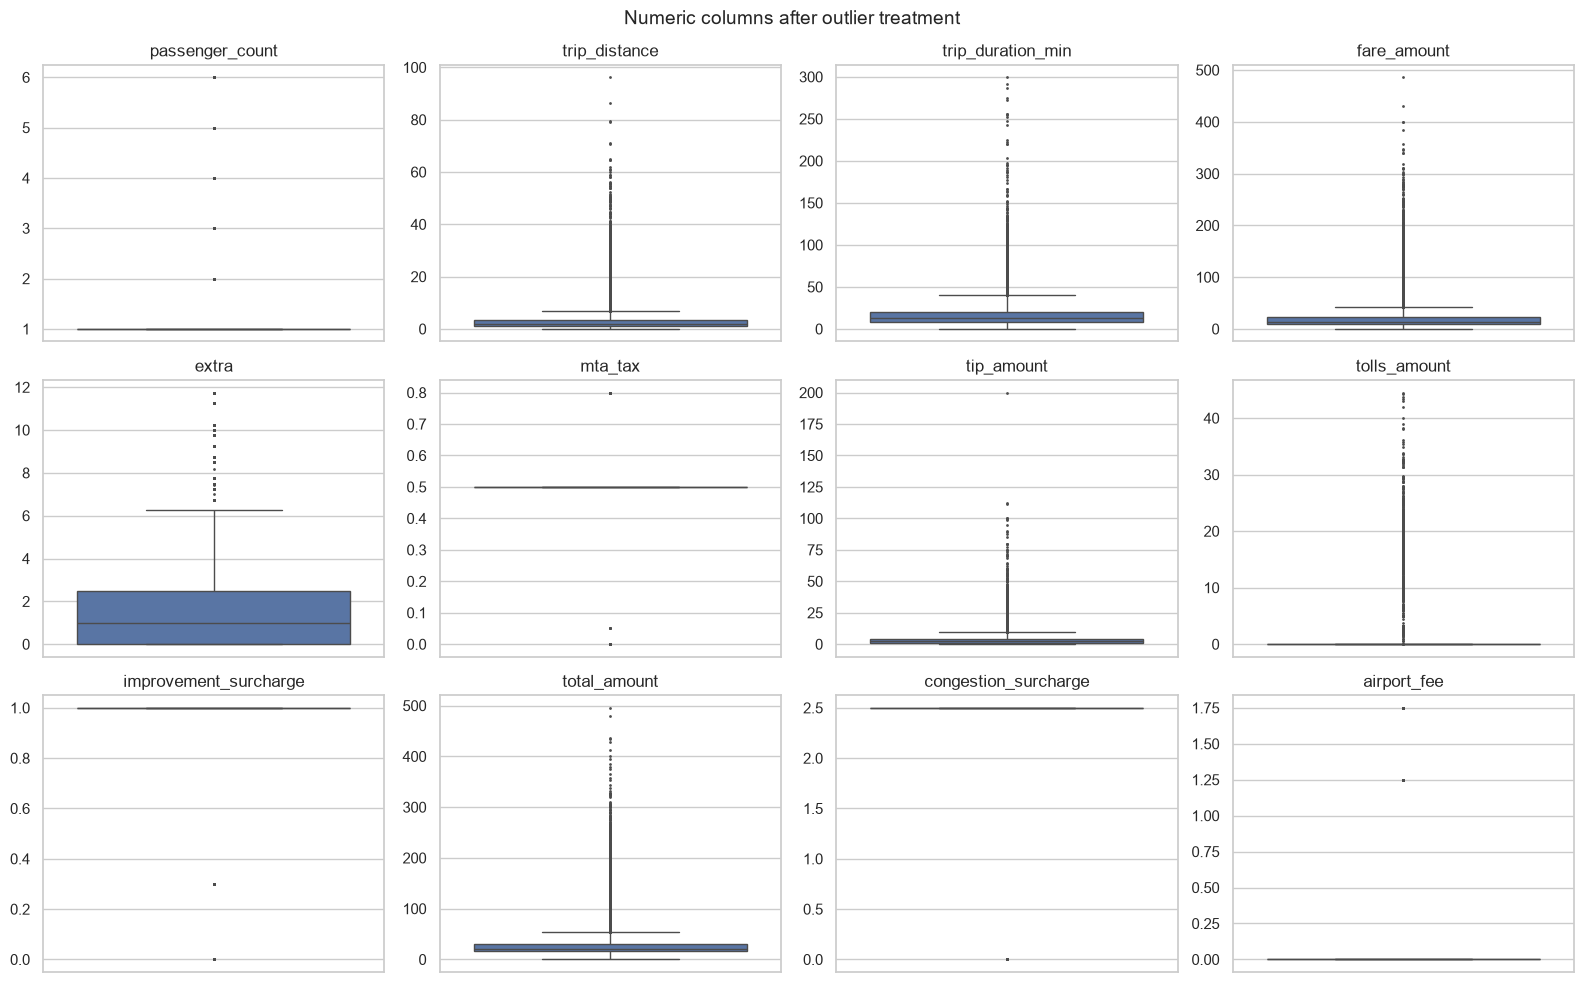

In [27]:
fig = plot_boxes(df, "Numeric columns after outlier treatment")
save(fig, "outliers_after")
plt.show()

**Observations**

* Seven trips with more than six passengers are removed. Larger groups exceed taxi capacity.
* The rules remove 526 further rows, or 0.18% of the data. Most are trips with a duration of zero or less, trips longer than five hours, or speeds above 80 mph, which point to meter or clock errors.
* The cleaned data has 283,908 trips. The maximum distance falls from 44,410 miles to 96 miles, and the maximum duration from about 24 hours to 5 hours.
* Trips with `payment_type` 0 are kept and labelled `Not recorded`. Recoding them as credit card payments would distort the payment and tip analysis.
* The columns are not standardised. Exploratory analysis needs values in their real units, such as dollars and miles.

In [28]:
df.to_parquet(PROCESSED_DIR / "trips_clean.parquet")
print(f"Clean trips: {len(df):,}")

Clean trips: 283,908


## 4. Demand patterns

The variables fall into the following types. The next cell adds time features used throughout the analysis.

| Type | Columns |
| --- | --- |
| Date and time | `tpep_pickup_datetime`, `tpep_dropoff_datetime` |
| Categorical | `VendorID`, `RatecodeID`, `PULocationID`, `DOLocationID`, `payment_type`, `pickup_day`, `is_weekend` |
| Ordinal | `pickup_hour`, `dropoff_hour`, `pickup_month`, `pickup_quarter` |
| Numerical | `passenger_count`, `trip_distance`, `trip_duration_min` and all monetary columns |

In [29]:
pickup = df["tpep_pickup_datetime"]
df["pickup_hour"] = pickup.dt.hour
df["pickup_day"] = pd.Categorical(pickup.dt.day_name(), categories=DAYS, ordered=True)
df["pickup_month"] = pickup.dt.month
df["pickup_quarter"] = pickup.dt.quarter
df["is_weekend"] = pickup.dt.dayofweek >= 5
df["dropoff_hour"] = df["tpep_dropoff_datetime"].dt.hour
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee',
 'trip_duration_min',
 'pickup_hour',
 'pickup_day',
 'pickup_month',
 'pickup_quarter',
 'is_weekend',
 'dropoff_hour']

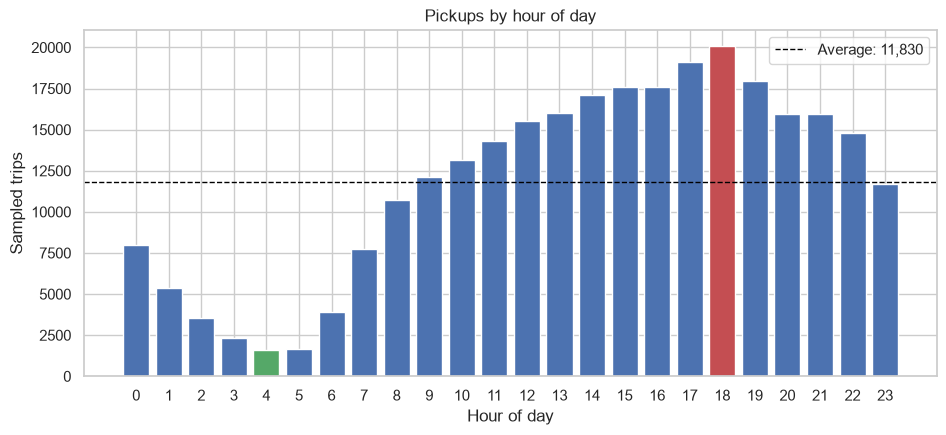

Busiest hour: 18:00 (20,070 trips). Quietest hour: 4:00 (1,589 trips).


In [30]:
hourly = df["pickup_hour"].value_counts().sort_index()
colours = ["#4C72B0"] * 24
colours[hourly.idxmax()] = "#C44E52"
colours[hourly.idxmin()] = "#55A868"

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(hourly.index, hourly.values, color=colours)
ax.axhline(hourly.mean(), color="black", linestyle="--", linewidth=1, label=f"Average: {hourly.mean():,.0f}")
ax.set(title="Pickups by hour of day", xlabel="Hour of day", ylabel="Sampled trips", xticks=range(24))
ax.legend()
save(fig, "pickups_by_hour")
plt.show()
print(f"Busiest hour: {hourly.idxmax()}:00 ({hourly.max():,} trips). "
      f"Quietest hour: {hourly.idxmin()}:00 ({hourly.min():,} trips).")

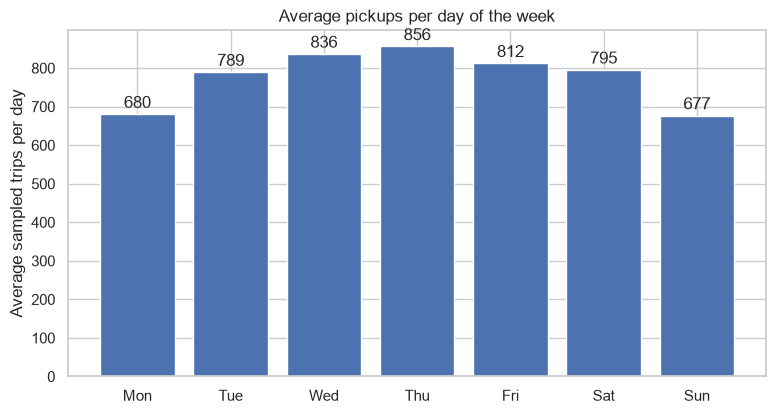

Busiest day: Thursday (856 trips per day). Quietest day: Sunday (677 trips per day).


In [31]:
trips_per_date = df.groupby(df["tpep_pickup_datetime"].dt.normalize()).size()
daily = trips_per_date.groupby(trips_per_date.index.day_name()).mean().reindex(DAYS)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar([d[:3] for d in DAYS], daily.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.0f", padding=2)
ax.set(title="Average pickups per day of the week", ylabel="Average sampled trips per day")
save(fig, "pickups_by_day")
plt.show()
print(f"Busiest day: {daily.idxmax()} ({daily.max():.0f} trips per day). "
      f"Quietest day: {daily.idxmin()} ({daily.min():.0f} trips per day).")

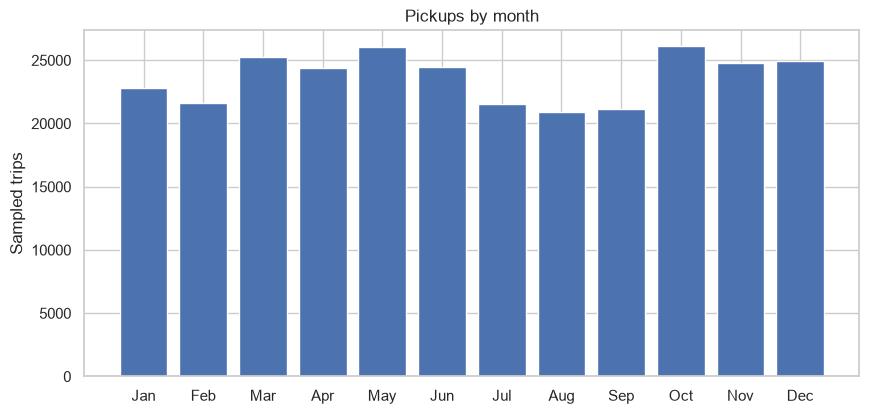

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
estimated_trips,3036000,2881000,3366000,3253000,3474000,3266000,2869000,2789000,2815000,3479000,3300000,3327000


In [32]:
monthly = df["pickup_month"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(MONTHS, monthly.values, color="#4C72B0")
ax.set(title="Pickups by month", ylabel="Sampled trips")
save(fig, "pickups_by_month")
plt.show()

estimated = (monthly / SAMPLE_FRACTION).round(-3).astype(int)
estimated.index = MONTHS
estimated.to_frame("estimated_trips").T

**Observations**

* Demand peaks at 18:00, when the sample records 20,070 pickups, and is lowest at 04:00, with 1,589 pickups.
* Thursday is the busiest day, at 856 sampled trips per day on average. Sunday is the quietest, at 677.
* May and October are the busiest months, with about 3.47 million trips each. August is the quietest month, with about 2.79 million.

## 5. Revenue and fares

Zero fares and totals are excluded from revenue analysis. Zero-distance trips are kept, because a trip that starts and ends in the same zone can still be valid and paid.

In [33]:
check_cols = ["fare_amount", "tip_amount", "total_amount", "trip_distance"]
pd.DataFrame({"zero": (df[check_cols] == 0).sum(), "negative": (df[check_cols] < 0).sum()})

,zero,negative
fare_amount,67,0
tip_amount,64988,0
total_amount,36,0
trip_distance,5448,0


In [34]:
df_fin = df[(df["fare_amount"] > 0) & (df["total_amount"] > 0)].copy()
print(f"Trips with a positive fare and total: {len(df_fin):,} of {len(df):,}")
print(f"Zero-distance trips kept: {(df_fin['trip_distance'] == 0).sum():,}")

Trips with a positive fare and total: 283,841 of 283,908
Zero-distance trips kept: 5,411


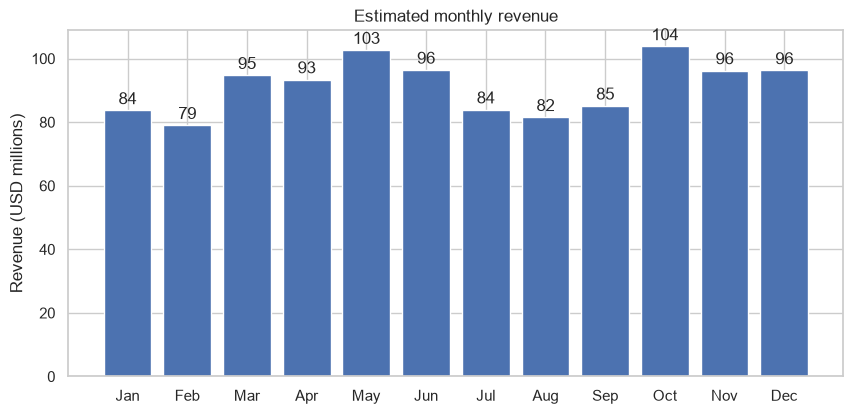

Estimated 2023 revenue: $1,097 million


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
usd_millions,83.7,79.0,94.7,93.4,102.6,96.4,83.9,81.5,85.1,103.8,96.2,96.3


In [35]:
monthly_revenue = df_fin.groupby("pickup_month")["total_amount"].sum() / SAMPLE_FRACTION / 1e6

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(MONTHS, monthly_revenue.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.0f", padding=2)
ax.set(title="Estimated monthly revenue", ylabel="Revenue (USD millions)")
save(fig, "monthly_revenue")
plt.show()
print(f"Estimated 2023 revenue: ${monthly_revenue.sum():,.0f} million")
monthly_revenue.set_axis(MONTHS).round(1).to_frame("usd_millions").T

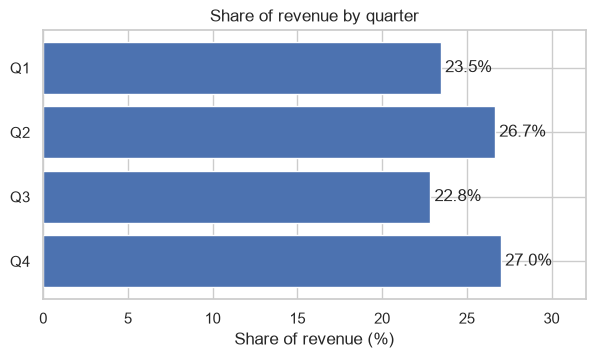

pickup_quarter,1,2,3,4
share_pct,23.5,26.7,22.8,27.0


In [36]:
quarterly = df_fin.groupby("pickup_quarter")["total_amount"].sum()
quarterly_share = quarterly / quarterly.sum() * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh([f"Q{q}" for q in quarterly_share.index], quarterly_share.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(title="Share of revenue by quarter", xlabel="Share of revenue (%)", xlim=(0, quarterly_share.max() + 5))
ax.invert_yaxis()
save(fig, "quarterly_revenue_share")
plt.show()
quarterly_share.round(1).to_frame("share_pct").T

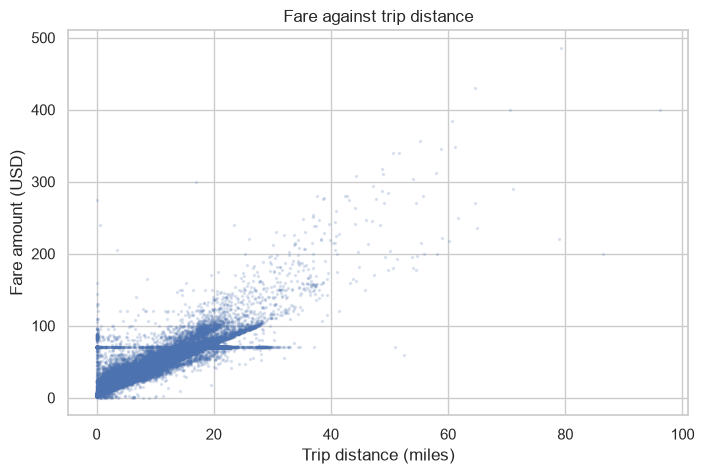

Correlation between distance and fare: 0.947


In [37]:
moving = df_fin[df_fin["trip_distance"] > 0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(moving["trip_distance"], moving["fare_amount"], s=2, alpha=0.15, color="#4C72B0")
ax.set(title="Fare against trip distance", xlabel="Trip distance (miles)", ylabel="Fare amount (USD)")
save(fig, "fare_vs_distance")
plt.show()
print(f"Correlation between distance and fare: {moving['trip_distance'].corr(moving['fare_amount']):.3f}")

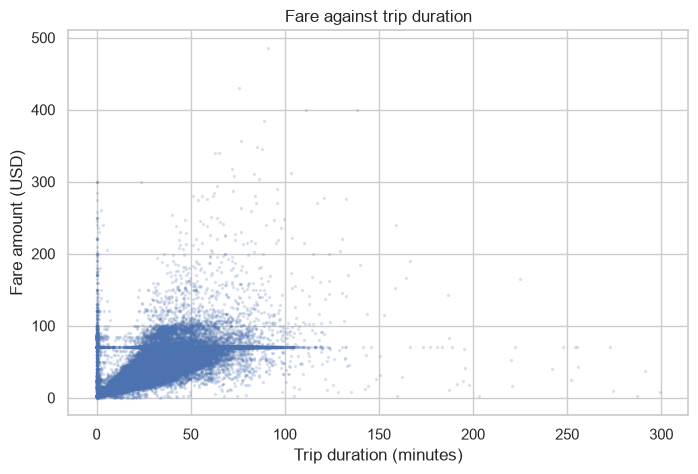

Correlation between duration and fare: 0.804


In [38]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df_fin["trip_duration_min"], df_fin["fare_amount"], s=2, alpha=0.15, color="#4C72B0")
ax.set(title="Fare against trip duration", xlabel="Trip duration (minutes)", ylabel="Fare amount (USD)")
save(fig, "fare_vs_duration")
plt.show()
print(f"Correlation between duration and fare: {df_fin['trip_duration_min'].corr(df_fin['fare_amount']):.3f}")

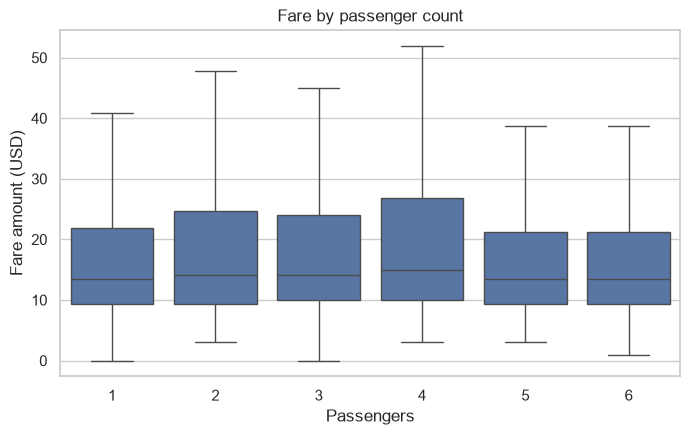

Correlation between passengers and fare: 0.045


In [39]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_fin, x="passenger_count", y="fare_amount", showfliers=False, color="#4C72B0", ax=ax)
ax.set(title="Fare by passenger count", xlabel="Passengers", ylabel="Fare amount (USD)")
save(fig, "fare_by_passengers")
plt.show()
print(f"Correlation between passengers and fare: {df_fin['passenger_count'].corr(df_fin['fare_amount']):.3f}")

Tips are recorded only for credit card payments, so the tip analysis uses credit card trips.

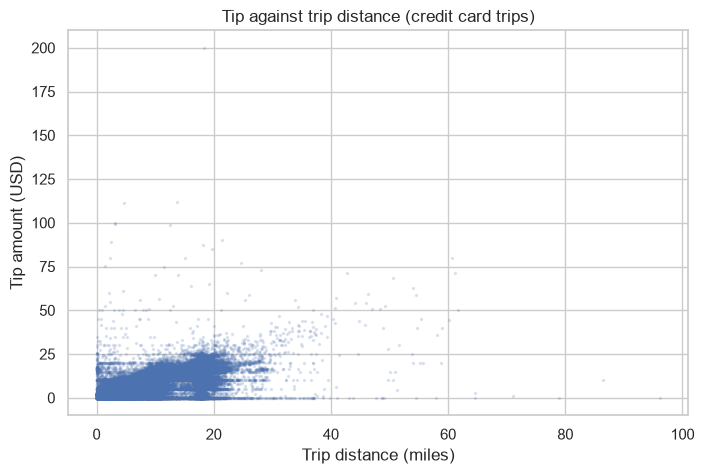

Credit card trips: 221,497
Correlation between distance and tip: 0.735


In [40]:
card = df_fin[(df_fin["payment_type"] == 1) & (df_fin["trip_distance"] > 0)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(card["trip_distance"], card["tip_amount"], s=2, alpha=0.15, color="#4C72B0")
ax.set(title="Tip against trip distance (credit card trips)", xlabel="Trip distance (miles)", ylabel="Tip amount (USD)")
save(fig, "tip_vs_distance")
plt.show()
print(f"Credit card trips: {len(card):,}")
print(f"Correlation between distance and tip: {card['trip_distance'].corr(card['tip_amount']):.3f}")

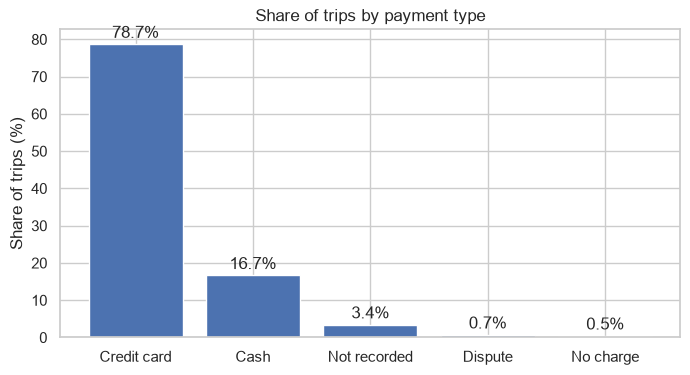

payment_type,Credit card,Cash,Not recorded,Dispute,No charge
share_pct,78.71,16.67,3.44,0.72,0.45


In [41]:
payment_share = df["payment_type"].map(PAYMENT_LABELS).value_counts(normalize=True).mul(100)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(payment_share.index, payment_share.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.1f%%", padding=2)
ax.set(title="Share of trips by payment type", ylabel="Share of trips (%)")
save(fig, "payment_types")
plt.show()
payment_share.round(2).to_frame("share_pct").T

**Observations**

* Estimated revenue for 2023 is about $1.10 billion. Monthly revenue ranges from $79 million in February to $104 million in October.
* The second and fourth quarters contribute 26.7% and 27.0% of revenue. The third quarter contributes the least, at 22.8%.
* Fare is strongly correlated with distance (0.947) and duration (0.804), because the meter charges for both.
* The correlation between passenger count and fare is close to zero (0.045). Yellow taxi fares do not depend on the number of passengers.
* On credit card trips, tip amount is strongly correlated with distance (0.735), because tips usually scale with the fare.
* Credit cards account for 78.7% of trips and cash for 16.7%. Payment type is not recorded for 3.4% of trips.

## 6. Geography

The shapefile has one polygon for each of the 263 taxi zones. Trip records also use IDs 264 and 265 for unknown and out-of-city locations, so these are added to the zone lookup with descriptive names.

In [42]:
zones = gpd.read_file(ZONES_FILE)
print(f"Zone polygons: {len(zones)}, unique location IDs: {zones['LocationID'].nunique()}")

zone_lookup = zones.set_index("LocationID")[["zone", "borough"]]
unknown = pd.DataFrame({"zone": ["Unknown", "Outside NYC"], "borough": ["Unknown", "Unknown"]}, index=[264, 265])
zone_lookup = pd.concat([zone_lookup, unknown])
zones.head()

Zone polygons: 263, unique location IDs: 263


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    str     
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    str     
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), str(2)
memory usage: 18.5 KB


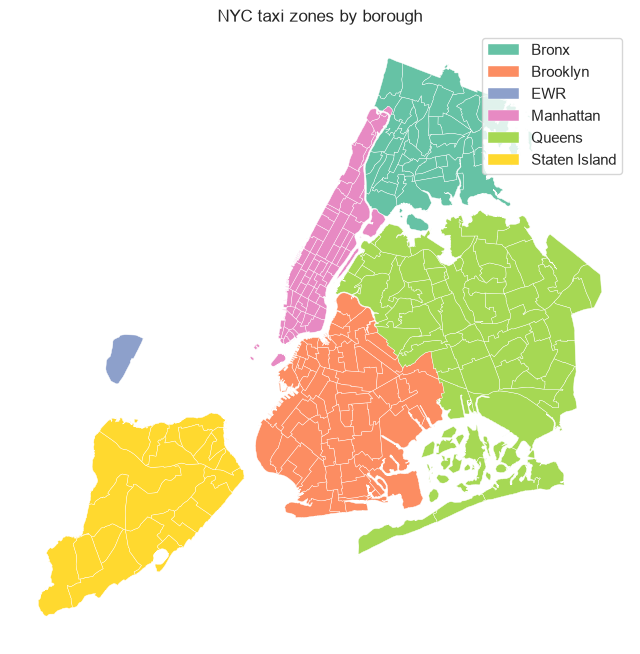

In [43]:
zones.info()

fig, ax = plt.subplots(figsize=(8, 8))
zones.plot(column="borough", ax=ax, legend=True, cmap="Set2", edgecolor="white", linewidth=0.3)
ax.set_title("NYC taxi zones by borough")
ax.set_axis_off()
save(fig, "taxi_zones")
plt.show()

In [44]:
trips_zones = df.merge(zone_lookup, left_on="PULocationID", right_index=True, how="left")
print(f"Rows before the merge: {len(df):,}. Rows after: {len(trips_zones):,}")
trips_zones[["PULocationID", "zone", "borough"]].head()

Rows before the merge: 283,908. Rows after: 283,908


,PULocationID,zone,borough
0,229,Sutton Place/Turtle Bay North,Manhattan
1,68,East Chelsea,Manhattan
2,170,Murray Hill,Manhattan
3,79,East Village,Manhattan
4,148,Lower East Side,Manhattan


In [45]:
trips_per_zone = df.groupby("PULocationID").size().rename("trip_count")
trips_per_zone.sort_values(ascending=False).head()

PULocationID
132    14736
237    13245
161    13194
236    11971
162    10072
Name: trip_count, dtype: int64

In [46]:
zones = zones.merge(trips_per_zone, left_on="LocationID", right_index=True, how="left")
zones["trip_count"] = zones["trip_count"].fillna(0)
zones[["LocationID", "zone", "borough", "trip_count"]].head()

,LocationID,zone,borough,trip_count
0,1,Newark Airport,EWR,49.0
1,2,Jamaica Bay,Queens,0.0
2,3,Allerton/Pelham Gardens,Bronx,7.0
3,4,Alphabet City,Manhattan,359.0
4,5,Arden Heights,Staten Island,4.0


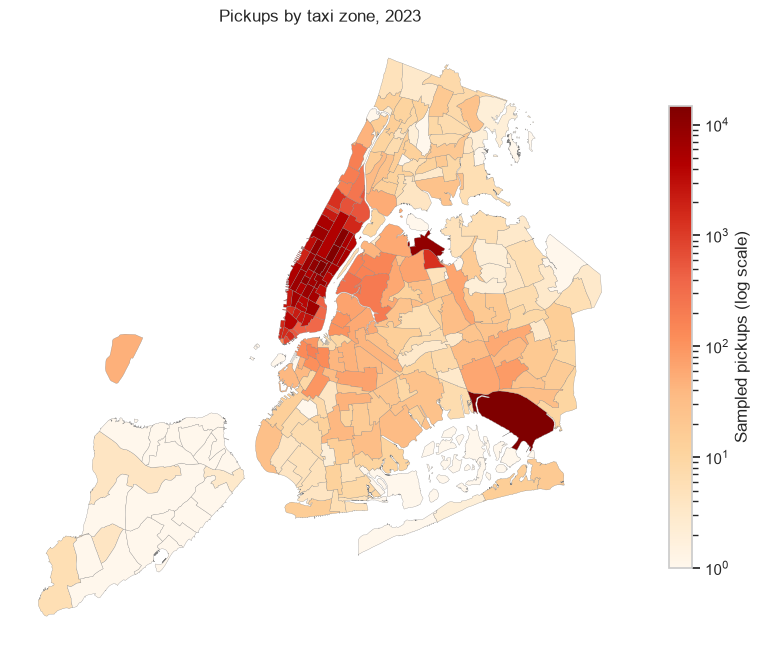

In [47]:
fig, ax = plt.subplots(figsize=(10, 10))
zones.assign(trips=zones["trip_count"].clip(lower=1)).plot(
    column="trips", ax=ax, cmap="OrRd", edgecolor="grey", linewidth=0.2,
    norm=LogNorm(vmin=1, vmax=zones["trip_count"].max()), legend=True,
    legend_kwds={"label": "Sampled pickups (log scale)", "shrink": 0.6},
)
ax.set_title("Pickups by taxi zone, 2023")
ax.set_axis_off()
save(fig, "pickups_by_zone")
plt.show()

In [48]:
busiest_zones = zones.sort_values("trip_count", ascending=False)[["LocationID", "zone", "borough", "trip_count"]].head(10)
busiest_zones["share_pct"] = (busiest_zones["trip_count"] / len(df) * 100).round(2)
busiest_zones

,LocationID,zone,borough,trip_count,share_pct
131,132,JFK Airport,Queens,14736.0,5.19
236,237,Upper East Side South,Manhattan,13245.0,4.67
160,161,Midtown Center,Manhattan,13194.0,4.65
235,236,Upper East Side North,Manhattan,11971.0,4.22
161,162,Midtown East,Manhattan,10072.0,3.55
185,186,Penn Station/Madison Sq West,Manhattan,9738.0,3.43
137,138,LaGuardia Airport,Queens,9463.0,3.33
141,142,Lincoln Square East,Manhattan,9414.0,3.32
229,230,Times Sq/Theatre District,Manhattan,9402.0,3.31
169,170,Murray Hill,Manhattan,8295.0,2.92


**Observations**

* JFK Airport is the busiest pickup zone, with 5.2% of all trips. Upper East Side South follows with 4.7% and Midtown Center with 4.6%.
* Eight of the ten busiest pickup zones are in Manhattan. The other two are JFK Airport and LaGuardia Airport.
* Pickups outside Manhattan and the airports are sparse. All 20 Staten Island zones, 24 of 43 Bronx zones and 30 of 69 Queens zones record fewer than 10 sampled pickups in the year.

## 7. Operational efficiency

### 7.1 Speed and slow routes

Route speed is the average distance divided by the average duration for each pickup zone, dropoff zone and hour. Only combinations with at least five sampled trips are compared, and trips within one zone are excluded.

In [49]:
moving = df[(df["trip_distance"] > 0) & (df["trip_duration_min"] > 0)]
routes = (
    moving.groupby(["PULocationID", "DOLocationID", "pickup_hour"])
    .agg(trips=("trip_distance", "size"), distance=("trip_distance", "mean"),
         duration_min=("trip_duration_min", "mean"))
    .reset_index()
)
routes["speed_mph"] = routes["distance"] / (routes["duration_min"] / 60)
routes = routes[(routes["trips"] >= 5) & (routes["PULocationID"] != routes["DOLocationID"])]
routes = routes.join(zone_lookup.add_prefix("pickup_"), on="PULocationID")
routes = routes.join(zone_lookup.add_prefix("dropoff_"), on="DOLocationID")

columns = ["pickup_zone", "dropoff_zone", "pickup_hour", "trips", "distance", "duration_min", "speed_mph"]
print(f"Route and hour combinations with at least 5 trips: {len(routes):,}")
routes.sort_values("speed_mph")[columns].head(10).round(2)

Route and hour combinations with at least 5 trips: 16,057


,pickup_zone,dropoff_zone,pickup_hour,trips,distance,duration_min,speed_mph
18375,Greenwich Village South,Greenwich Village North,13,6,0.70,25.24,1.67
40018,Midtown South,Garment District,17,8,0.63,15.82,2.38
43596,Penn Station/Madison Sq West,Garment District,14,9,0.56,11.61,2.88
38034,Midtown East,Times Sq/Theatre District,13,31,0.94,19.08,2.95
15080,Garment District,Midtown South,13,7,0.59,11.97,2.95
61392,World Trade Center,TriBeCa/Civic Center,17,5,0.62,12.59,2.96
43602,Penn Station/Madison Sq West,Garment District,20,6,0.58,11.38,3.05
40528,Midtown South,Penn Station/Madison Sq West,15,8,0.63,12.37,3.07
7054,East Chelsea,Garment District,13,10,0.83,16.17,3.09
43598,Penn Station/Madison Sq West,Garment District,16,8,0.50,9.51,3.17


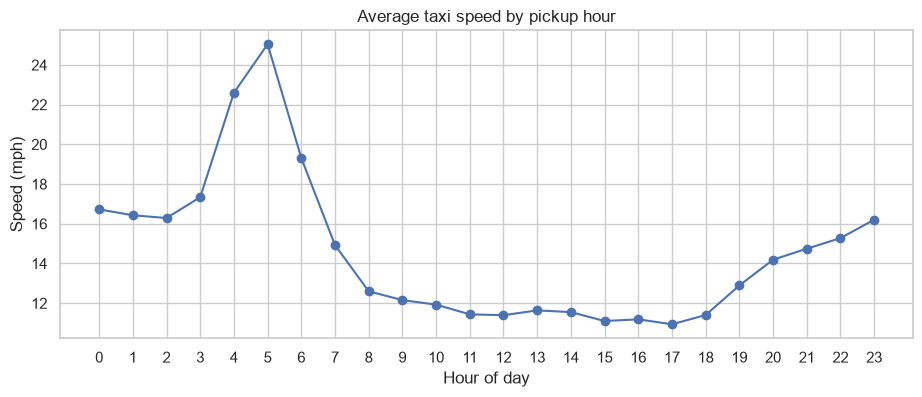

Slowest hour: 17:00 (10.9 mph). Fastest hour: 5:00 (25.0 mph).


In [50]:
totals = moving.groupby("pickup_hour")[["trip_distance", "trip_duration_min"]].sum()
speed_by_hour = totals["trip_distance"] / (totals["trip_duration_min"] / 60)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(speed_by_hour.index, speed_by_hour.values, marker="o", color="#4C72B0")
ax.set(title="Average taxi speed by pickup hour", xlabel="Hour of day", ylabel="Speed (mph)", xticks=range(24))
save(fig, "speed_by_hour")
plt.show()
print(f"Slowest hour: {speed_by_hour.idxmin()}:00 ({speed_by_hour.min():.1f} mph). "
      f"Fastest hour: {speed_by_hour.idxmax()}:00 ({speed_by_hour.max():.1f} mph).")

**Observations**

* Taxis are slowest at 17:00, averaging 10.9 mph, and fastest at 05:00, averaging 25.0 mph.
* Average speed stays between 10.9 and 12.6 mph from 08:00 to 18:00.
* The slowest routes are short trips within Midtown and Lower Manhattan, around the Garment District, Penn Station and Midtown South. Several average under 3 mph at midday and in the evening peak.

### 7.2 Hourly demand

Counts from the sample are divided by the sampling fraction to estimate the number of trips in 2023.

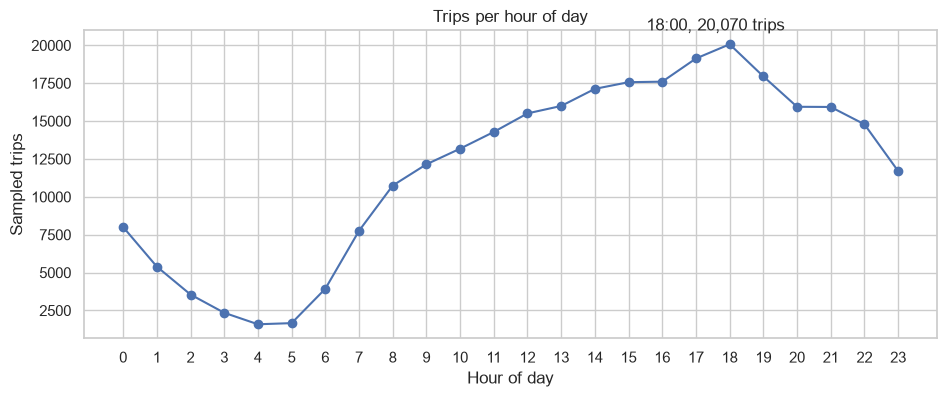

Busiest hour: 18:00 with 20,070 sampled trips


In [51]:
busiest = hourly.idxmax()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hourly.index, hourly.values, marker="o", color="#4C72B0")
ax.annotate(f"{busiest}:00, {hourly[busiest]:,} trips", (busiest, hourly[busiest]),
            textcoords="offset points", xytext=(-60, 10))
ax.set(title="Trips per hour of day", xlabel="Hour of day", ylabel="Sampled trips", xticks=range(24))
plt.show()
print(f"Busiest hour: {busiest}:00 with {hourly[busiest]:,} sampled trips")

In [52]:
top_hours = hourly.nlargest(5).to_frame("sampled_trips")
top_hours["estimated_trips"] = (top_hours["sampled_trips"] / SAMPLE_FRACTION).round(-3).astype(int)
top_hours

,sampled_trips,estimated_trips
pickup_hour,,
18,20070,2676000
17,19132,2551000
19,17949,2393000
16,17602,2347000
15,17567,2342000


Weekdays outnumber weekend days five to two, so the comparison uses average trips per day rather than totals.

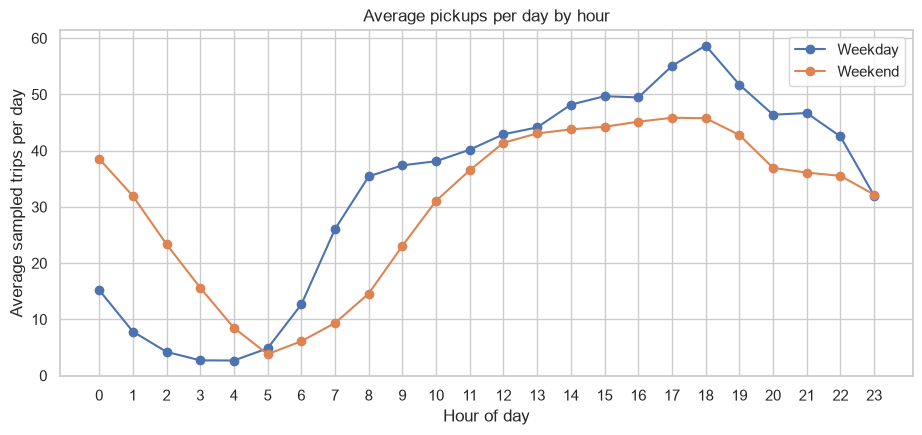

Peak weekday hour: 18 | Peak weekend hour: 17


In [53]:
day_type = df["is_weekend"].map({False: "Weekday", True: "Weekend"})
days_per_type = df.groupby(df["tpep_pickup_datetime"].dt.normalize())["is_weekend"].first().map(
    {False: "Weekday", True: "Weekend"}).value_counts()
pattern = df.groupby([df["pickup_hour"], day_type]).size().unstack().div(days_per_type)

fig, ax = plt.subplots(figsize=(11, 4.5))
pattern.plot(ax=ax, marker="o")
ax.set(title="Average pickups per day by hour", xlabel="Hour of day",
       ylabel="Average sampled trips per day", xticks=range(24))
ax.legend(title="")
save(fig, "weekday_vs_weekend")
plt.show()
print("Peak weekday hour:", pattern["Weekday"].idxmax(), "| Peak weekend hour:", pattern["Weekend"].idxmax())

**Observations**

* An estimated 2.68 million trips start between 18:00 and 19:00 across 2023, the busiest hour of the year.
* The five busiest hours, from 15:00 to 19:00, each have more than 2.3 million trips.
* Weekdays have a commuter pattern. Demand rises steeply from 06:00 to 08:00 and peaks at 18:00.
* Weekends have a late-night pattern. Pickups at midnight are 2.5 times the weekday level, and the morning rise starts about two hours later.

### 7.3 Busy zones, flows and night activity

Top 10 pickup zones: JFK Airport, Upper East Side South, Midtown Center, Upper East Side North, Midtown East, Penn Station/Madison Sq West, LaGuardia Airport, Lincoln Square East, Times Sq/Theatre District, Murray Hill


Top 10 dropoff zones: Upper East Side North, Upper East Side South, Midtown Center, Times Sq/Theatre District, Murray Hill, Midtown East, Upper West Side South, Lincoln Square East, Lenox Hill West, East Chelsea


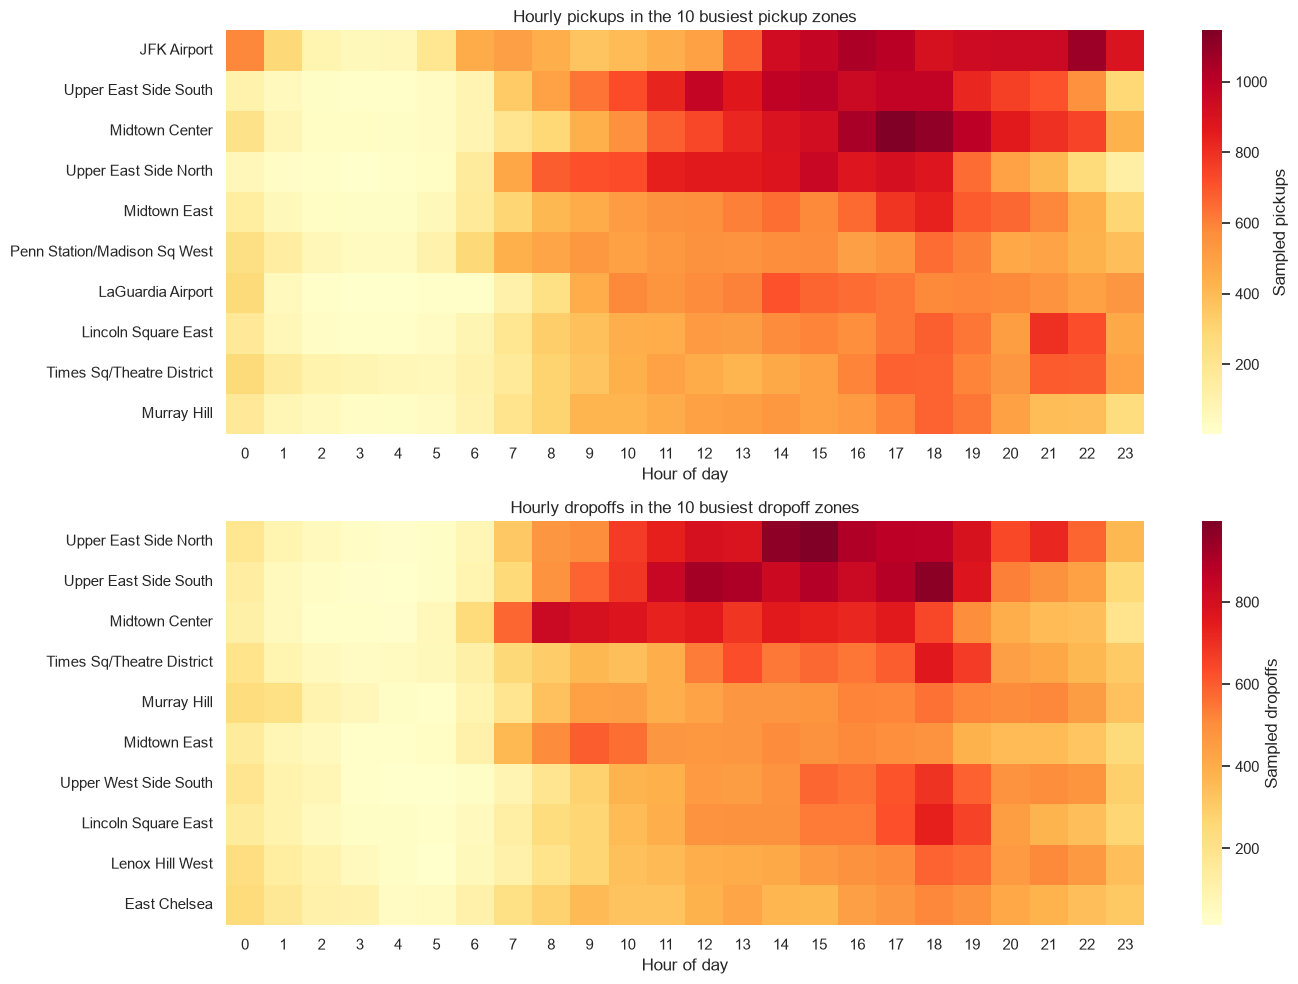

In [54]:
def zone_hour_table(location_col, hour_col):
    top = df[location_col].value_counts().head(10).index
    table = (df[df[location_col].isin(top)].groupby([location_col, hour_col]).size()
             .unstack(fill_value=0).reindex(top))
    table.index = zone_lookup.loc[table.index, "zone"]
    return table


fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, (location_col, hour_col, label) in zip(axes, [("PULocationID", "pickup_hour", "pickups"),
                                                    ("DOLocationID", "dropoff_hour", "dropoffs")]):
    table = zone_hour_table(location_col, hour_col)
    sns.heatmap(table, cmap="YlOrRd", ax=ax, cbar_kws={"label": f"Sampled {label}"})
    ax.set(title=f"Hourly {label} in the 10 busiest {label[:-1]} zones", xlabel="Hour of day", ylabel="")
    print(f"Top 10 {label[:-1]} zones:", ", ".join(table.index))
fig.tight_layout()
save(fig, "top_zones_by_hour")
plt.show()

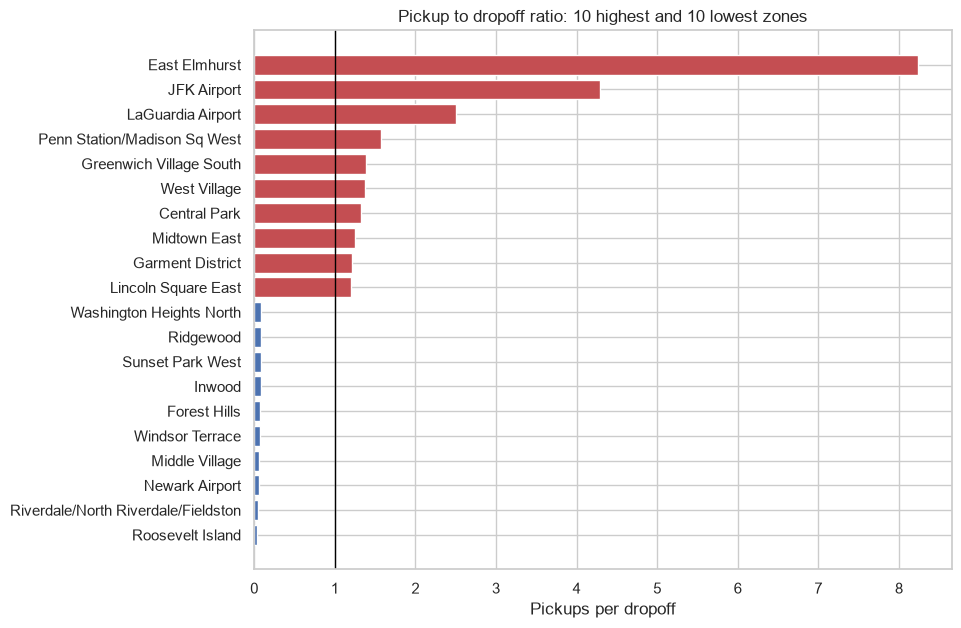

,zone,borough,pickups,dropoffs,ratio
70,East Elmhurst,Queens,1294.0,157.0,8.24
132,JFK Airport,Queens,14736.0,3431.0,4.29
138,LaGuardia Airport,Queens,9463.0,3774.0,2.51
186,Penn Station/Madison Sq West,Manhattan,9738.0,6203.0,1.57
114,Greenwich Village South,Manhattan,3717.0,2688.0,1.38
249,West Village,Manhattan,6347.0,4614.0,1.38
43,Central Park,Manhattan,4666.0,3527.0,1.32
162,Midtown East,Manhattan,10072.0,8080.0,1.25
100,Garment District,Manhattan,4689.0,3846.0,1.22
142,Lincoln Square East,Manhattan,9414.0,7814.0,1.20


,zone,borough,pickups,dropoffs,ratio
243,Washington Heights North,Manhattan,45.0,508.0,0.09
198,Ridgewood,Queens,14.0,167.0,0.08
228,Sunset Park West,Brooklyn,14.0,168.0,0.08
127,Inwood,Manhattan,16.0,200.0,0.08
95,Forest Hills,Queens,32.0,410.0,0.08
257,Windsor Terrace,Brooklyn,8.0,109.0,0.07
160,Middle Village,Queens,6.0,104.0,0.06
1,Newark Airport,EWR,49.0,876.0,0.06
200,Riverdale/North Riverdale/Fieldston,Bronx,5.0,96.0,0.05
202,Roosevelt Island,Manhattan,7.0,171.0,0.04


In [55]:
flow = pd.DataFrame({"pickups": df["PULocationID"].value_counts(),
                     "dropoffs": df["DOLocationID"].value_counts()}).fillna(0)
flow = flow[(flow["pickups"] + flow["dropoffs"] >= 100) & (flow["dropoffs"] > 0)]
flow["ratio"] = flow["pickups"] / flow["dropoffs"]
flow = flow.join(zone_lookup).sort_values("ratio", ascending=False)

extremes = pd.concat([flow.head(10), flow.tail(10)])
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(extremes["zone"], extremes["ratio"], color=["#C44E52"] * 10 + ["#4C72B0"] * 10)
ax.axvline(1, color="black", linewidth=1)
ax.set(title="Pickup to dropoff ratio: 10 highest and 10 lowest zones", xlabel="Pickups per dropoff")
ax.invert_yaxis()
save(fig, "pickup_dropoff_ratio")
plt.show()

columns = ["zone", "borough", "pickups", "dropoffs", "ratio"]
display(flow[columns].head(10).round(2))
display(flow[columns].tail(10).round(2))

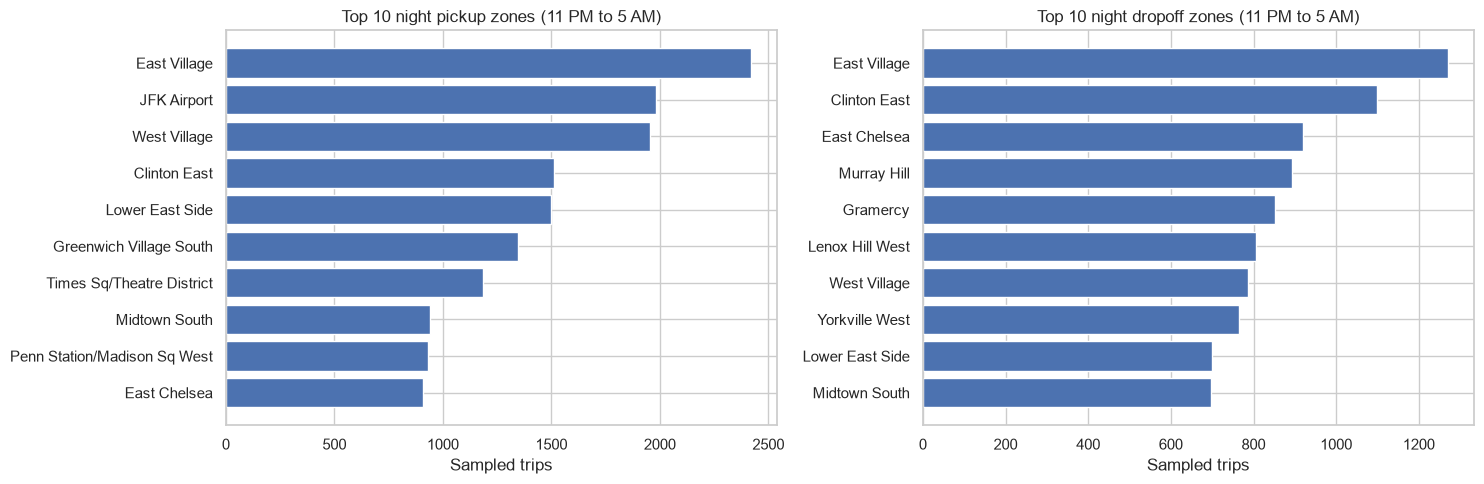

Night trips: 32,587 (11.5% of all trips)


In [56]:
night = df[df["pickup_hour"].isin(NIGHT_HOURS)]
night_pickups = night["PULocationID"].value_counts().head(10)
night_dropoffs = night["DOLocationID"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, counts, label in [(axes[0], night_pickups, "pickup"), (axes[1], night_dropoffs, "dropoff")]:
    ax.barh(zone_lookup.loc[counts.index, "zone"], counts.values, color="#4C72B0")
    ax.set(title=f"Top 10 night {label} zones (11 PM to 5 AM)", xlabel="Sampled trips")
    ax.invert_yaxis()
fig.tight_layout()
save(fig, "night_zones")
plt.show()
print(f"Night trips: {len(night):,} ({len(night) / len(df):.1%} of all trips)")

In [57]:
period = df_fin["pickup_hour"].isin(NIGHT_HOURS).map({True: "Night", False: "Day"})
revenue_split = pd.DataFrame({
    "revenue_share_pct": df_fin.groupby(period)["total_amount"].sum() / df_fin["total_amount"].sum() * 100,
    "trip_share_pct": period.value_counts(normalize=True) * 100,
    "average_total_usd": df_fin.groupby(period)["total_amount"].mean(),
}).round(2)
revenue_split

,revenue_share_pct,trip_share_pct,average_total_usd
pickup_hour,,,
Day,88.52,88.52,28.98
Night,11.48,11.48,28.99


**Observations**

* JFK Airport is busy from 14:00 until midnight, and its peak comes at 22:00. Manhattan zones peak in the afternoon and early evening.
* Dropoffs in Midtown Center peak from 08:00 to 10:00, which reflects commuting into the business district.
* East Elmhurst, JFK Airport and LaGuardia Airport have far more pickups than dropoffs, with 8.2, 4.3 and 2.5 pickups per dropoff. East Elmhurst borders LaGuardia, so many of its pickups are likely airport trips. Taxis arrive at the airports empty and leave with passengers.
* Residential zones in upper Manhattan, Queens and Brooklyn receive many dropoffs but few pickups. Taxis that end trips there often return empty.
* Night trips, from 11 PM to 5 AM, make up 11.5% of trips and 11.5% of revenue. The average night fare matches the daytime average.
* East Village, JFK Airport and the West Village lead night pickups. East Village also leads night dropoffs.

## 8. Pricing

Fare per mile is calculated as total fares divided by total miles in each group. A simple average of per-trip ratios would be dominated by very short trips, where a fixed starting charge is spread over a fraction of a mile.

In [58]:
def fare_per_mile(data, by):
    totals = data.groupby(by, observed=True)[["fare_amount", "trip_distance"]].sum()
    return totals["fare_amount"] / totals["trip_distance"]


priced = df_fin[df_fin["trip_distance"] > 0].copy()
priced["distance_tier"] = pd.cut(priced["trip_distance"], [0, 2, 5, np.inf],
                                 labels=["Up to 2 miles", "2 to 5 miles", "Over 5 miles"])

per_passenger = fare_per_mile(priced, "passenger_count").to_frame("fare_per_mile")
per_passenger["fare_per_mile_per_passenger"] = per_passenger["fare_per_mile"] / per_passenger.index
per_passenger["trips"] = priced["passenger_count"].value_counts()
per_passenger.round(2)

,fare_per_mile,fare_per_mile_per_passenger,trips
passenger_count,,,
1,5.68,5.68,215061
2,5.37,2.69,41460
3,5.52,1.84,10208
4,5.48,1.37,5687
5,5.59,1.12,3643
6,5.60,0.93,2371


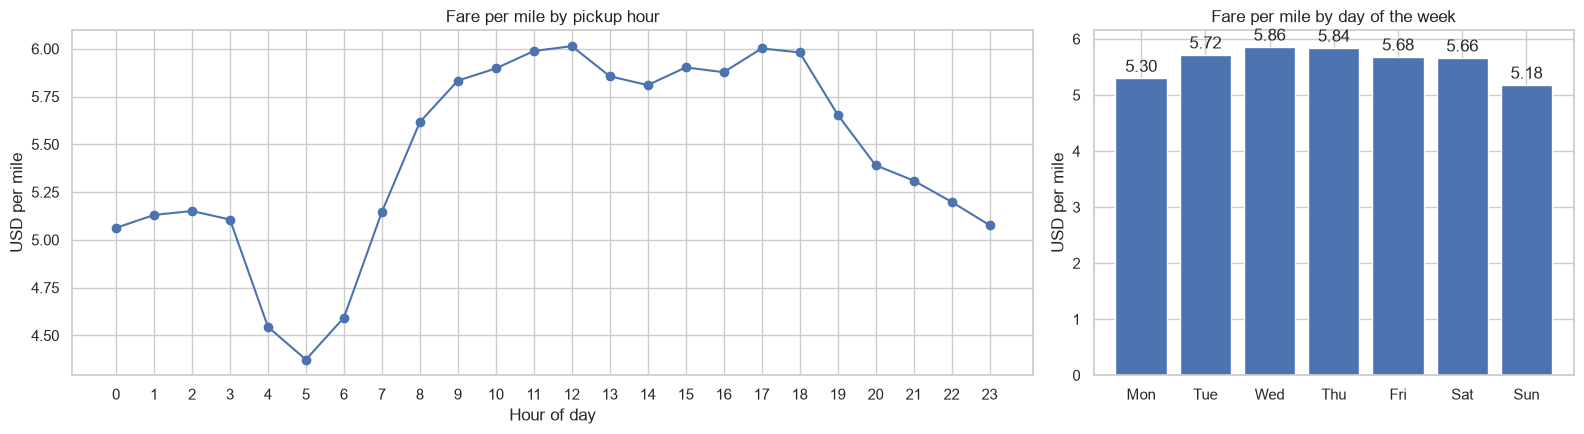

Highest hour: 12:00 ($6.01). Lowest hour: 5:00 ($4.37).


pickup_day,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
usd_per_mile,5.3,5.72,5.86,5.84,5.68,5.66,5.18


In [59]:
by_hour = fare_per_mile(priced, "pickup_hour")
by_day = fare_per_mile(priced, "pickup_day")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(by_hour.index, by_hour.values, marker="o", color="#4C72B0")
axes[0].set(title="Fare per mile by pickup hour", xlabel="Hour of day", ylabel="USD per mile", xticks=range(24))
bars = axes[1].bar([d[:3] for d in by_day.index], by_day.values, color="#4C72B0")
axes[1].bar_label(bars, fmt="%.2f", padding=2)
axes[1].set(title="Fare per mile by day of the week", ylabel="USD per mile")
fig.tight_layout()
save(fig, "fare_per_mile_by_time")
plt.show()
print(f"Highest hour: {by_hour.idxmax()}:00 (${by_hour.max():.2f}). Lowest hour: {by_hour.idxmin()}:00 (${by_hour.min():.2f}).")
by_day.round(2).to_frame("usd_per_mile").T

VendorID
VeriFone                        206362
Creative Mobile Technologies     72019
Vendor 6                            49


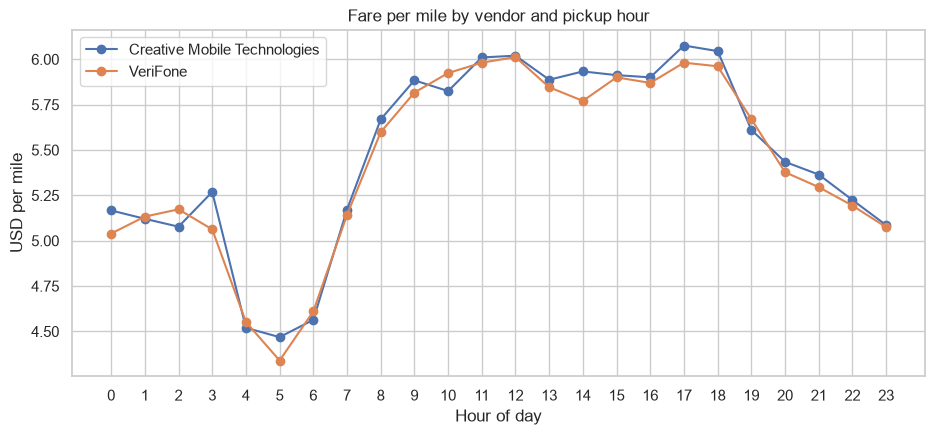

In [60]:
print(priced["VendorID"].map(VENDOR_LABELS).value_counts().to_string())
vendor_hour = fare_per_mile(priced, ["pickup_hour", "VendorID"]).unstack().rename(columns=VENDOR_LABELS)

fig, ax = plt.subplots(figsize=(11, 4.5))
vendor_hour.drop(columns="Vendor 6", errors="ignore").plot(ax=ax, marker="o")
ax.set(title="Fare per mile by vendor and pickup hour", xlabel="Hour of day", ylabel="USD per mile", xticks=range(24))
ax.legend(title="")
save(fig, "fare_per_mile_by_vendor")
plt.show()

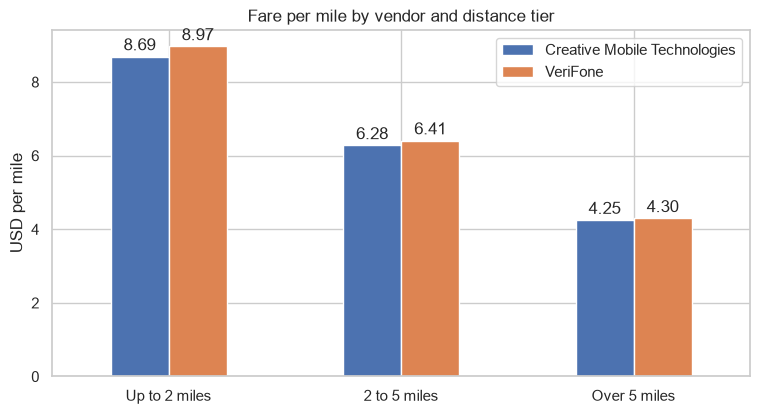

VendorID,Creative Mobile Technologies,VeriFone,Vendor 6
distance_tier,,,
Up to 2 miles,8.69,8.97,94.17
2 to 5 miles,6.28,6.41,7.68
Over 5 miles,4.25,4.30,4.43


In [61]:
tiers = fare_per_mile(priced, ["distance_tier", "VendorID"]).unstack().rename(columns=VENDOR_LABELS)

fig, ax = plt.subplots(figsize=(9, 4.5))
tiers.drop(columns="Vendor 6", errors="ignore").plot(kind="bar", ax=ax, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)
ax.set(title="Fare per mile by vendor and distance tier", xlabel="", ylabel="USD per mile")
ax.legend(title="")
save(fig, "fare_per_mile_by_tier")
plt.show()
tiers.round(2)

**Observations**

* Fare per mile is about $5.40 to $5.70 regardless of passenger count. Fare per mile per passenger therefore falls from $5.68 for one passenger to $0.93 for six.
* Fare per mile is highest from 09:00 to 18:00, at about $5.80 to $6.00, and lowest at 05:00, at $4.37. This mirrors the speed chart, because the meter also charges for slow traffic.
* Fare per mile is highest from Tuesday to Thursday, peaking at $5.86 on Wednesday, and lowest on Sunday, at $5.18.
* The two main vendors charge almost identical rates. Their fare per mile differs by at most $0.21 in any hour. In both cases, fare per mile falls from about $9 for trips under 2 miles to about $4.30 for trips over 5 miles.
* Vendor 6 has only 49 sampled trips and is excluded from the vendor charts.

## 9. Customer experience

Tip rate is total tips divided by total fares for credit card trips in each group.

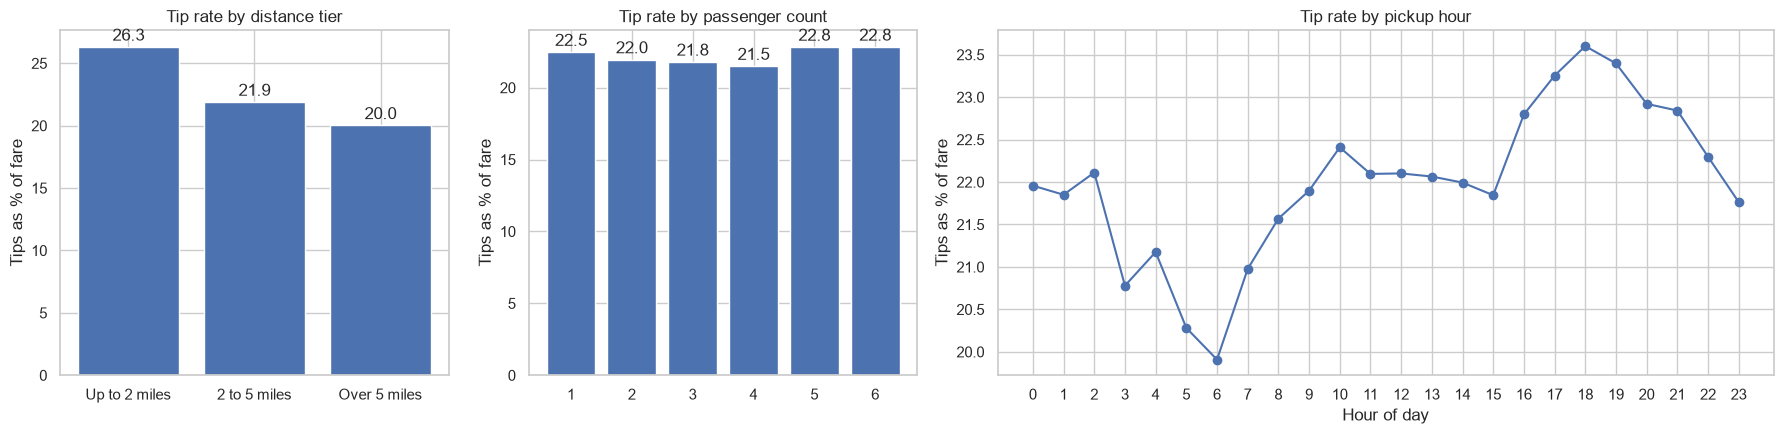

Overall tip rate on credit card trips: 22.3%


distance_tier,Up to 2 miles,2 to 5 miles,Over 5 miles
tip_rate_pct,26.3,21.9,20.0


In [62]:
tipped = priced[priced["payment_type"] == 1].copy()


def tip_rate(by):
    totals = tipped.groupby(by, observed=True)[["tip_amount", "fare_amount"]].sum()
    return totals["tip_amount"] / totals["fare_amount"] * 100


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [1, 1, 2]})
for ax, (by, title) in zip(axes[:2], [("distance_tier", "distance tier"), ("passenger_count", "passenger count")]):
    rates = tip_rate(by)
    bars = ax.bar(rates.index.astype(str), rates.values, color="#4C72B0")
    ax.bar_label(bars, fmt="%.1f", padding=2)
    ax.set(title=f"Tip rate by {title}", ylabel="Tips as % of fare")
by_hour_tips = tip_rate("pickup_hour")
axes[2].plot(by_hour_tips.index, by_hour_tips.values, marker="o", color="#4C72B0")
axes[2].set(title="Tip rate by pickup hour", xlabel="Hour of day", ylabel="Tips as % of fare", xticks=range(24))
fig.tight_layout()
save(fig, "tip_rate")
plt.show()
print(f"Overall tip rate on credit card trips: {tipped['tip_amount'].sum() / tipped['fare_amount'].sum():.1%}")
tip_rate("distance_tier").round(1).to_frame("tip_rate_pct").T

In [63]:
tipped["tip_pct"] = tipped["tip_amount"] / tipped["fare_amount"] * 100
tipped["airport_trip"] = tipped["airport_fee"] > 0
groups = tipped["tip_pct"].map(lambda p: "Low (under 10%)" if p < 10 else "High (over 25%)" if p > 25 else None)
compare = tipped.groupby(groups)[["trip_distance", "fare_amount", "trip_duration_min", "passenger_count",
                                  "airport_trip"]].mean()
compare["trips"] = groups.value_counts()
compare.T.round(2)

tip_pct,High (over 25%),Low (under 10%)
trip_distance,2.31,4.84
fare_amount,14.43,25.66
trip_duration_min,12.28,21.41
passenger_count,1.37,1.37
airport_trip,0.05,0.11
trips,121775.00,21204.00


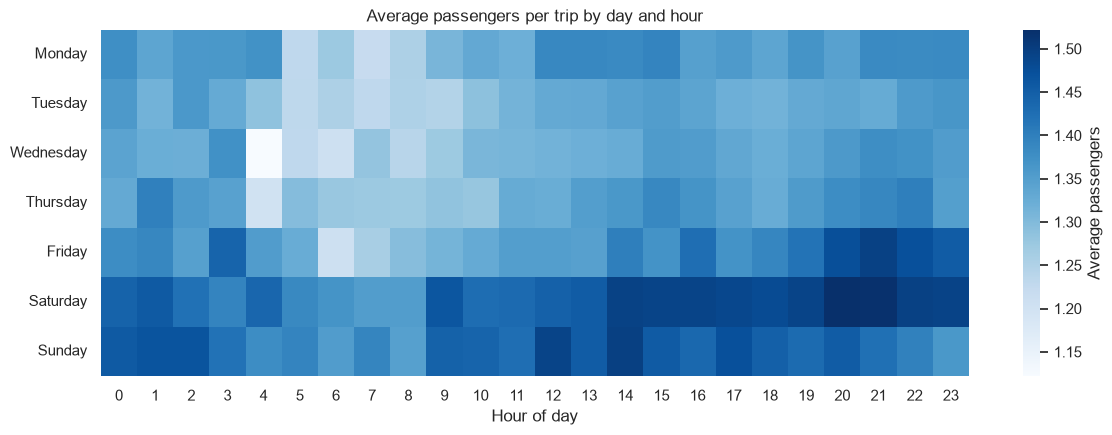

Average passengers per trip: 1.38
Share of single-passenger trips: 77.4%


In [64]:
occupancy = df.pivot_table(index="pickup_day", columns="pickup_hour", values="passenger_count",
                           aggfunc="mean", observed=True)

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(occupancy, cmap="Blues", ax=ax, cbar_kws={"label": "Average passengers"})
ax.set(title="Average passengers per trip by day and hour", xlabel="Hour of day", ylabel="")
save(fig, "passengers_by_day_hour")
plt.show()
print(f"Average passengers per trip: {df['passenger_count'].mean():.2f}")
print(f"Share of single-passenger trips: {(df['passenger_count'] == 1).mean():.1%}")

In [65]:
zone_passengers = df.groupby("PULocationID")["passenger_count"].agg(["mean", "size"])
zone_passengers = zone_passengers[zone_passengers["size"] >= 100].join(zone_lookup)
zone_passengers = zone_passengers.sort_values("mean", ascending=False)
display(zone_passengers.head(10).round(2))
display(zone_passengers.tail(10).round(2))

,mean,size,zone,borough
PULocationID,,,,
12,1.67,130,Battery Park,Manhattan
209,1.54,532,Seaport,Manhattan
132,1.51,14736,JFK Airport,Queens
88,1.51,784,Financial District South,Manhattan
45,1.50,421,Chinatown,Manhattan
261,1.50,1503,World Trade Center,Manhattan
43,1.49,4666,Central Park,Manhattan
230,1.48,9402,Times Sq/Theatre District,Manhattan
148,1.45,2913,Lower East Side,Manhattan


,mean,size,zone,borough
PULocationID,,,,
152,1.27,179,Manhattanville,Manhattan
145,1.25,288,Long Island City/Hunters Point,Queens
226,1.25,214,Sunnyside,Queens
74,1.23,584,East Harlem North,Manhattan
42,1.23,248,Central Harlem North,Manhattan
255,1.22,101,Williamsburg (North Side),Brooklyn
244,1.20,190,Washington Heights South,Manhattan
7,1.19,156,Astoria,Queens
193,1.18,171,Queensbridge/Ravenswood,Queens


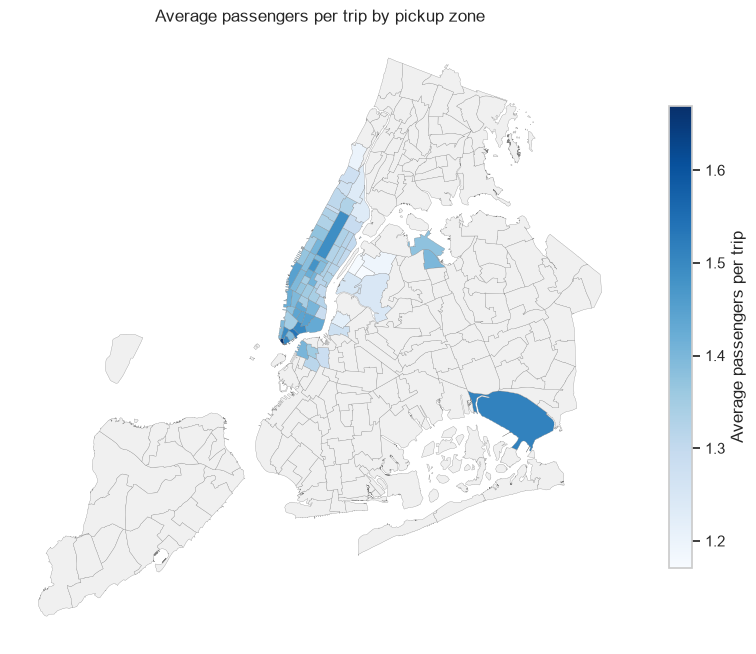

In [66]:
passenger_map = zones.merge(zone_passengers[["mean"]], left_on="LocationID", right_index=True, how="left")

fig, ax = plt.subplots(figsize=(10, 10))
passenger_map.plot(column="mean", ax=ax, cmap="Blues", edgecolor="grey", linewidth=0.2, legend=True,
                   legend_kwds={"label": "Average passengers per trip", "shrink": 0.6},
                   missing_kwds={"color": "#f0f0f0", "label": "Fewer than 100 trips"})
ax.set_title("Average passengers per trip by pickup zone")
ax.set_axis_off()
save(fig, "passengers_by_zone")
plt.show()

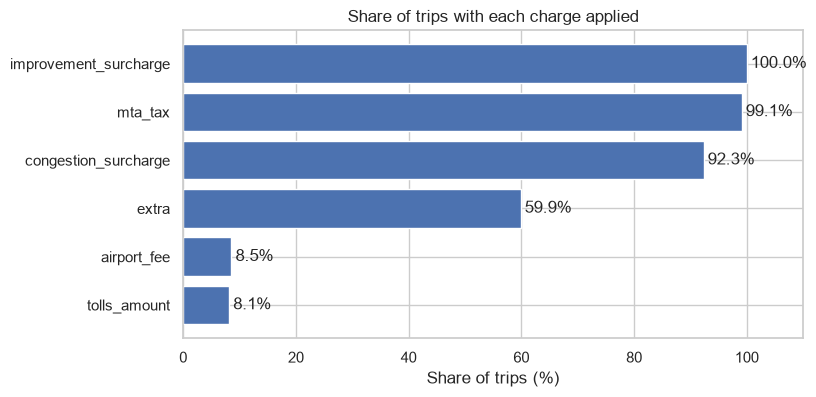

,tolls_amount,airport_fee,extra,congestion_surcharge,mta_tax,improvement_surcharge
share_pct,8.1,8.5,59.9,92.3,99.1,100.0


In [67]:
frequency = df[SURCHARGES].gt(0).mean().mul(100).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(frequency.index, frequency.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(title="Share of trips with each charge applied", xlabel="Share of trips (%)", xlim=(0, 110))
save(fig, "surcharge_frequency")
plt.show()
frequency.round(1).to_frame("share_pct").T

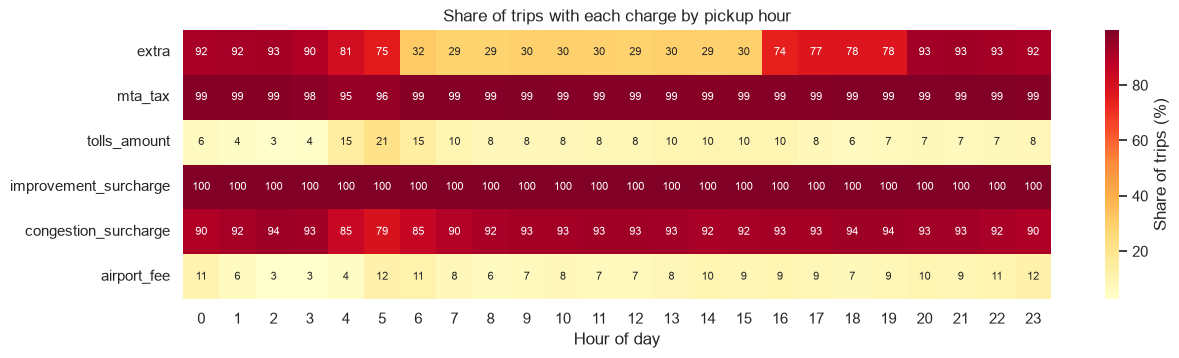

,extra,mta_tax,tolls_amount,improvement_surcharge,congestion_surcharge,airport_fee
PULocationID,,,,,,
Bronx,9.6,95.1,23.5,99.0,6.7,0.4
Brooklyn,27.4,97.0,9.0,99.7,31.0,0.2
EWR,6.1,8.2,8.2,100.0,0.0,0.0
Manhattan,59.6,99.3,3.2,100.0,97.6,0.1
Queens,66.4,97.8,52.5,99.9,52.8,86.5
Staten Island,20.0,80.0,75.0,95.0,0.0,0.0
Unknown,50.2,94.5,12.2,99.6,69.1,7.4


Top zones by airport_fee:


,zone,borough,airport_fee
PULocationID,,,
138,LaGuardia Airport,Queens,97.7
132,JFK Airport,Queens,93.1
70,East Elmhurst,Queens,66.4
264,Unknown,Unknown,8.0
145,Long Island City/Hunters Point,Queens,2.1


Top zones by tolls_amount:


,zone,borough,tolls_amount
PULocationID,,,
70,East Elmhurst,Queens,64.5
138,LaGuardia Airport,Queens,63.9
132,JFK Airport,Queens,48.7
145,Long Island City/Hunters Point,Queens,16.0
264,Unknown,Unknown,12.2


In [68]:
by_hour = df[SURCHARGES].gt(0).groupby(df["pickup_hour"]).mean().mul(100)

fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(by_hour.T, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 8}, ax=ax,
            cbar_kws={"label": "Share of trips (%)"})
ax.set(title="Share of trips with each charge by pickup hour", xlabel="Hour of day", ylabel="")
save(fig, "surcharges_by_hour")
plt.show()

borough = df["PULocationID"].map(zone_lookup["borough"])
display(df[SURCHARGES].gt(0).groupby(borough).mean().mul(100).round(1))

zone_rates = df[["congestion_surcharge", "airport_fee", "tolls_amount"]].gt(0).groupby(df["PULocationID"]).mean()
zone_rates = zone_rates[df["PULocationID"].value_counts().reindex(zone_rates.index) >= 100].mul(100).join(zone_lookup)
for col in ["airport_fee", "tolls_amount"]:
    print(f"Top zones by {col}:")
    display(zone_rates.sort_values(col, ascending=False)[["zone", "borough", col]].head(5).round(1))

**Observations**

* Credit card passengers tip 22.3% of the fare on average. Short trips under 2 miles receive the highest tip rate, at 26.3%. Trips over 5 miles receive the lowest, at 20.0%.
* Tip rates peak in the evening, from 17:00 to 19:00, and are lowest in the early morning, from 05:00 to 06:00.
* Trips with tips under 10% are twice as long and twice as likely to involve an airport as trips with tips over 25%. Passenger count is the same in both groups.
* 77.4% of trips carry a single passenger. Groups are larger on Friday and Saturday evenings and around the Financial District, Battery Park and JFK Airport.
* Every trip pays the improvement surcharge, and 99.1% pay the MTA tax. The congestion surcharge applies to 92.3% of trips, the time-based extra to 59.9%, the airport fee to 8.5% and tolls to 8.1%.
* The extra charge applies mainly from 16:00 to 05:00, which matches the rush-hour and overnight surcharges.
* The congestion surcharge applies to 97.6% of Manhattan pickups but only 6.7% of Bronx pickups. Airport fees and tolls concentrate at JFK, LaGuardia and East Elmhurst.

## 10. Conclusions and recommendations

### Data

* The analysis uses a 0.75% stratified sample of 2023 yellow taxi trips, drawn by date and hour, which reproduces the monthly distribution of all 38.3 million trips.
* Cleaning removed 1.2% of sampled rows. These were mostly reversed charges, timing errors and impossible distances or speeds. Missing fees were inferred from each trip's fare breakdown.

### Routing and dispatch

* Increase supply from 15:00 to 19:00 on weekdays. The busiest hour, 18:00, carries about 2.7 million trips a year, and speeds fall to about 11 mph.
* Shift weekend supply later. Weekend pickups at midnight are 2.5 times the weekday level, while weekend mornings start about two hours later.
* Avoid short Midtown routes around Penn Station, the Garment District and Midtown South at midday and 17:00, when average speeds fall below 3 mph on some routes.

### Positioning

* Keep a queue at JFK and LaGuardia from the afternoon until midnight. Airports produce 2.5 to 4.3 pickups for every dropoff.
* Concentrate daytime supply in Midtown and the Upper East Side. These zones lead both pickups and dropoffs, and Midtown dropoffs peak during the morning commute.
* Position cars in the East Village, the West Village and at JFK from 11 PM to 5 AM, when these zones lead pickups.
* Limit empty returns from residential zones in upper Manhattan, Queens, Brooklyn and the Bronx, where dropoffs outnumber pickups by more than ten to one.

### Pricing

* Fares already rise with congestion, from $4.37 per mile at 05:00 to about $6.00 per mile in the afternoon. Further surcharges should target the 15:00 to 19:00 peak rather than the whole day.
* Consider a lower per-passenger rate or a group product. Fares do not change with group size, so fare per passenger falls by 84% from one to six passengers.
* Review long and airport trips. They receive the lowest tip rates, which reduces driver earnings per hour on the longest journeys.